<center>
  <img src="https://upload.wikimedia.org/wikipedia/commons/6/68/Logo_FPT_Education.png" width="300" alt="FPT Education logo"  />
</center>

# ADY201m - AI, DATA SCIENCE WITH PYTHON & SQL
### REPORT 1 (ONGOING ASSESSMENT 1)
**Topic:** Business Understanding, Data Collection & Data Cleaning

---

### PROJECT INFORMATION
- **Project Title:** Predicting Electric Vehicle Purchase Propensity for Customer Targeting
- **Class Code:** [Fill in class code, e.g., SE1801]
- **Group Name/ID:** [Fill in group name or ID]
- **Member List:**
  1. [Full Name - Student ID - Role in Group]
  2. [Full Name - Student ID - Role in Group]
  3. [Full Name - Student ID - Role in Group]
- **Dataset Source Link:** https://www.kaggle.com/competitions/playground-series-s6e9
- **Submission Date:** [Format DD/MM/YYYY]

---

## GRADING RUBRIC

*(This section is reserved for the instructor to grade and evaluate student work)*

| Criteria | Assessment Content | Max Score | Score Achieved | Lecturer's Feedback |
| :--- | :--- | :---: | :---: | :--- |
| **1. Business Understanding** | Clear and realistic statement of business context, business questions, and Data Science goal. | **2.5 pts** | | |
| **2. Data Collection & Inspection** | Accurate description of data source, data dictionary, data loading, and structural inspection. | **2.5 pts** | | |
| **3. Data Cleaning & Preprocessing** | Standard cleaning code (Missing values, Duplicates, Data types, Outliers) with rationale for chosen methods. | **4.0 pts** | | |
| **4. Discussion & Conclusion** | Assessment of data readiness, Before/After comparison table, and logical next steps. | **1.0 pt** | | |
| **TOTAL SCORE** | **Overall evaluation of Report 1 execution** | **10.0 pts** | | |

---

# PART 1: BUSINESS UNDERSTANDING [2.5 POINTS]

### Key Guidelines:
1. **Business Context:** Where does the real-world problem originate? What issue is the business/organization facing?
2. **Business Questions:** What 2–3 core business questions need to be answered to support decision-making?
3. **Data Science Formulation:** Define the problem type (Supervised/Unsupervised, Classification/Regression/Clustering) and target variable.

---

#### STUDENT TASK 1.1: BUSINESS CONTEXT & PROJECT JUSTIFICATION
*(Briefly present 150–300 words explaining the real-world context and motivation for choosing this project)*

**STUDENT RESPONSE:**

- **Business Context:** Trong xu thế chuyển dịch sang phương tiện xanh, một đại lý phân phối ô tô muốn đẩy mạnh tiếp thị dòng xe điện (EV). Khác với ô tô truyền thống, quyết định mua xe điện chịu chi phối lớn bởi hạ tầng trạm sạc, cự ly di chuyển, thu nhập và tâm lý lo ngại về pin. Thiếu công cụ định lượng khiến đội ngũ bán hàng gặp khó khăn trong việc nhận diện khách hàng thực sự quan tâm.

- **Core Problem to Solve:** Vấn đề trọng tâm là đại lý chưa thể phân loại nhóm khách hàng có tiềm năng mua xe điện cao, dẫn đến tiếp thị dàn trải và gia tăng chi phí. Dự án khai thác bộ dữ liệu quan sát gồm thông tin nhân khẩu, hạ tầng sạc, thói quen đi lại và mức độ quan tâm môi trường để xây dựng mô hình dự báo xác suất nhãn mục tiêu `Will_Buy_EV`.

- **Business Value / Significance:** Kết quả dự báo hỗ trợ đại lý tối ưu chi phí tiếp thị và ưu tiên nguồn lực tư vấn cho tệp khách hàng tiềm năng. Đây là nghiên cứu mô hình hóa dựa trên dữ liệu quan sát để tìm quy luật thống kê, không khẳng định quan hệ nhân quả hay cam kết giao dịch thương mại thực tế.

#### STUDENT TASK 1.2: CORE BUSINESS QUESTIONS
*(List at least 2–3 specific business questions that the analysis or model will answer)*

**STUDENT RESPONSE:**

1. **Question 1 (Khả năng dự báo - Predictive Feasibility):** Mô hình học máy phân loại có thể dự đoán đáng tin cậy xác suất khách hàng có nhãn `Will_Buy_EV` = "Yes" dựa trên các đặc trưng quan sát (nhân khẩu, thói quen di chuyển, hạ tầng sạc) hay không?
2. **Question 2 (Mối liên hệ thống kê - Feature Association):** Những yếu tố quan sát nào (như khả năng sạc tại nhà, thu nhập hàng năm, mức lo âu về tầm vận hành pin, chính sách trợ cấp) có mối liên hệ thống kê rõ rệt nhất với xu hướng mua xe điện trong dữ liệu?
3. **Question 3 (Hỗ trợ ra quyết định - Decision Support):** Đại lý có thể ứng dụng kết quả xác suất dự báo như thế nào để phân tầng khách hàng, ưu tiên nguồn lực tư vấn và thiết kế thông điệp tiếp cận phù hợp cho từng nhóm?

#### STUDENT TASK 1.3: DATA SCIENCE PROBLEM FORMULATION
*(Describe the problem details from a Data Science perspective)*

**STUDENT RESPONSE:**

- **Problem Type:** Phân loại nhị phân (Binary Classification) thuộc học có giám sát (Supervised Learning).

- **Target Variable (y):** Biến mục tiêu là `Will_Buy_EV` (chuỗi phân loại trong `dataset/train.csv`, không có trong `dataset/test.csv`):
  - `"No"`: 551.886 bản ghi (chiếm 82,54%) — Nhóm không có ý định mua xe điện trong dữ liệu quan sát.
  - `"Yes"`: 116.779 bản ghi (chiếm 17,46%) — Nhóm có ý định mua xe điện trong dữ liệu quan sát.
  *(Lưu ý: Nhãn ghi nhận ý định trong khảo sát dữ liệu, không phải dữ liệu giao dịch thương mại đã hoàn tất).*

- **Expected Feature Variables (X):** Tập hợp 13 thuộc tính quan sát ứng viên (loại trừ `id`):
  - *Nhân khẩu học & Kinh tế:* `Age` (int64, từ 25 đến 69 tuổi), `Gender` (str: Male, Female, Other), `Annual_Income_USD` (float64, từ 30.000 đến 188.549 USD).
  - *Thói quen đi lại & Sở hữu xe:* `Daily_Commute_km` (float64, từ 5,0 đến 98,7 km), `Number_of_Cars_Owned` (int64, từ 1 đến 4 xe), `Current_Car_Type` (str: Sedan, SUV, Hatchback, Truck).
  - *Hạ tầng sạc & Không gian sống:* `City_Type` (str: Urban, Suburban, Rural), `Charging_Stations_Near_Home` (int64, từ 0 đến 14 trạm), `Charging_Stations_Near_Work` (int64, từ 0 đến 19 trạm), `Home_Charging_Possible` (str: Yes, No).
  - *Chính sách & Thái độ tâm lý:* `Subsidy_Available` (str: Yes, No), `Environmental_Concern_Level` (float64, thang điểm 1.0 đến 5.0), `Range_Anxiety_Level` (str: Low, Medium, High).
  - *Cột định danh (`id`):* Cột `id` (int64) là mã số bản ghi, không mang tính quy luật dự báo và sẽ được loại bỏ khỏi ma trận đặc trưng đầu vào mô hình.

- **Evaluation Metric:** Dữ liệu có sự mất cân bằng lớp rõ rệt (82,54% `"No"` vs. 17,46% `"Yes"`), nên độ chính xác tổng thể (Accuracy) dễ gây hiểu nhầm (mô hình dự đoán toàn bộ là `"No"` vẫn đạt 82,54% nhưng vô giá trị thực tế). Hệ thống chỉ số đánh giá được thiết lập gồm:
  - *Chỉ số chính (Primary Metric):* **F1-score cho lớp `"Yes"`**, cân bằng giữa Precision (đúng khách hàng tiềm năng) và Recall (hạn chế bỏ sót khách hàng).
  - *Chỉ số hỗ trợ:* **PR-AUC (Precision-Recall AUC)** được ưu tiên theo dõi trên toàn dải ngưỡng cho lớp thiểu số; **ROC-AUC** dùng để đánh giá năng lực phân tách tổng quát.
  - *Phân tích sai số:* **Ma trận nhầm lẫn (Confusion Matrix)** giúp kiểm soát False Positives (lãng phí chi phí tư vấn) và False Negatives (bỏ lỡ cơ hội bán hàng).
  - *Accuracy:* Chỉ dùng làm số liệu tham khảo bổ trợ.

- **Validation Strategy (Kế hoạch cho Ongoing 2):**
  - Sử dụng phương pháp phân tầng (**Stratified K-Fold** hoặc Stratified Split 80/20) trên tập có nhãn `dataset/train.csv` (668.665 bản ghi) để duy trì tỷ lệ nhãn ~17,46% lớp `"Yes"` trên các tập con. Tập `dataset/test.csv` hoàn toàn không có nhãn nên không dùng để đánh giá mô hình.
  - **Nguyên tắc chống rò rỉ dữ liệu (Anti-Leakage):** Mọi bộ biến đổi (scaler, encoder) chỉ được `fit` trên tập huấn luyện của từng fold rồi áp dụng (`transform`) sang tập kiểm định tương ứng.
  - *Lưu ý:* Trong phạm vi Ongoing 1, nhóm chỉ tập trung làm sạch và chuẩn bị dữ liệu; chưa thực hiện chia tập hay huấn luyện mô hình.

# PART 2: DATA COLLECTION & INITIAL DATA UNDERSTANDING [2.5 POINTS]

### Key Guidelines:
1. Detail the data source (Kaggle, UCI, Web Scraping, SQL Database, etc.).
2. Create a **Data Dictionary** table explaining the meaning of each column and initial data types.
3. Write Python code to load data and display initial dataset statistics.

---

### DATA COLLECTION OVERVIEW (TỔNG QUAN THU THẬP DỮ LIỆU)

- **Nguồn dữ liệu (Data Source):** Cuộc thi **Kaggle Playground Series (Season 6, Episode 9)** với chủ đề *"Predicting Electric Vehicle Purchases"*.
  - Đường dẫn nguồn: [https://www.kaggle.com/competitions/playground-series-s6e9](https://www.kaggle.com/competitions/playground-series-s6e9)
- **Các tệp dữ liệu trong thư mục `dataset/`:**
  1. `dataset/train.csv`: Gồm **668.665 dòng** và **15 cột** (14 đặc trưng và biến mục tiêu `Will_Buy_EV`). Tệp này dùng để khám phá cấu trúc, làm sạch dữ liệu và huấn luyện mô hình ở các giai đoạn sau.
  2. `dataset/test.csv`: Gồm **286.571 dòng** và **14 cột** (không có nhãn `Will_Buy_EV`), đóng vai trò là tập kiểm thử độc lập ngoài mẫu.
  3. `dataset/sample_submission.csv`: Gồm **286.571 dòng** và **2 cột** (`id`, `Will_Buy_EV`), là tệp định dạng nộp bài chuẩn của Kaggle, không dùng để huấn luyện.
- **Nguyên tắc bảo toàn dữ liệu:** Các tệp trong `dataset/` được truy cập ở chế độ chỉ đọc (read-only), giữ nguyên dữ liệu gốc trong suốt quá trình nghiên cứu.

#### STUDENT TASK 2.1: DATA DICTIONARY
*(List all attributes in the project dataset)*

👉 **GROUP DATA DICTIONARY:**

| No. | Column Name | Original Data Type | Variable Type (Numeric/Categorical) | Business Meaning (Diễn giải nghiệp vụ dự kiến) | Example Value |
| :---: | :--- | :---: | :---: | :--- | :---: |
| 1 | `id` | `int64` | Identifier | Mã định danh số nguyên duy nhất cho từng bản ghi trong dataset | `0` |
| 2 | `Age` | `int64` | Numeric (Discrete) | Độ tuổi của đối tượng quan sát trong dataset (miền giá trị: 25 – 69 tuổi) | `47` |
| 3 | `Gender` | `String / Object` | Categorical (Nominal) | Giới tính của khách hàng (`Male`, `Female`, `Other`) | `"Male"` |
| 4 | `Annual_Income_USD` | `float64` | Numeric (Continuous) | Thu nhập hàng năm của khách hàng tính bằng USD ($30.000 – $188.549) | `84880.0` |
| 5 | `Daily_Commute_km` | `float64` | Numeric (Continuous) | Quãng đường di chuyển đi làm hàng ngày tính bằng km (5,0 – 98,7 km) | `33.6` |
| 6 | `Number_of_Cars_Owned` | `int64` | Numeric (Discrete) | Số lượng ô tô hiện đang sở hữu trong hộ gia đình (1, 2, 3, 4 xe) | `2` |
| 7 | `Current_Car_Type` | `String / Object` | Categorical (Nominal) | Dòng xe ô tô hiện tại đang sử dụng (`Sedan`, `SUV`, `Hatchback`, `Truck`) | `"Sedan"` |
| 8 | `City_Type` | `String / Object` | Categorical (Nominal) | Loại hình khu vực sinh sống của khách hàng (`Urban`, `Suburban`, `Rural`) | `"Urban"` |
| 9 | `Charging_Stations_Near_Home` | `int64` | Numeric (Discrete) | Số lượng trạm sạc xe điện sẵn có gần khu vực nhà ở (0 – 14 trạm) | `4` |
| 10 | `Charging_Stations_Near_Work` | `int64` | Numeric (Discrete) | Số lượng trạm sạc xe điện sẵn có gần nơi làm việc (0 – 19 trạm) | `6` |
| 11 | `Home_Charging_Possible` | `String / Object` | Categorical (Binary) | Khả năng lắp đặt hoặc tiếp cận trạm sạc tại nhà (`Yes`, `No`) | `"Yes"` |
| 12 | `Subsidy_Available` | `String / Object` | Categorical (Binary) | Khu vực có chính sách trợ cấp tài chính mua xe điện (`Yes`, `No`) | `"Yes"` |
| 13 | `Environmental_Concern_Level` | `float64` | Numeric / Ordinal | Mức độ quan tâm đến môi trường theo thang đo ghi nhận trong dataset (1.0 – 5.0) | `3.0` |
| 14 | `Range_Anxiety_Level` | `String / Object` | Categorical (Ordinal) | Mức độ lo ngại về tầm vận hành của pin xe điện (`Low`, `Medium`, `High`) | `"Low"` |
| 15 | `Will_Buy_EV` | `String / Object` | Categorical (Binary / Target) | Biến mục tiêu: Ý định/xu hướng mua xe điện trong tương lai (`No`, `Yes`) | `"No"` |

*Ghi chú học thuật:* Bảng thuộc tính được đối soát trực tiếp từ schema thực tế của file `dataset/train.csv`. Ý nghĩa kinh doanh dựa trên tên cột tiêu chuẩn và thông tin công bố từ bộ dữ liệu benchmark; không tự suy đoán thông tin ngoài dữ liệu thực tế.

#### STUDENT TASK 2.2: DATA LOADING & INITIAL STRUCTURE INSPECTION
*Write Python code to load the dataset and print key dataset statistics.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Cấu hình hiển thị và định dạng đồ họa
pd.set_option('display.max_columns', 20)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. Khai báo đường dẫn tương đối an toàn
DATA_DIR = Path('dataset')
train_path = DATA_DIR / 'train.csv'
test_path = DATA_DIR / 'test.csv'
sub_path = DATA_DIR / 'sample_submission.csv'

# 2. Đọc tập dữ liệu huấn luyện chính
df_raw = pd.read_csv(train_path)

# 3. Hiển thị kích thước các file dữ liệu
print("=== KÍCH THƯỚC BỘ DỮ LIỆU ===")
print(f"- Tập huấn luyện (train.csv): {df_raw.shape[0]:,} dòng, {df_raw.shape[1]} cột")

df_test_first = pd.read_csv(test_path, nrows=1)
test_rows = sum(1 for _ in open(test_path, 'r', encoding='utf-8')) - 1
print(f"- Tập kiểm thử (test.csv): {test_rows:,} dòng, {len(df_test_first.columns)} cột")

# 4. Xem trước 5 dòng đầu và 5 dòng cuối của train.csv
print("\n--- 5 DÒNG ĐẦU TIÊN (head) ---")
display(df_raw.head())

print("\n--- 5 DÒNG CUỐI CÙNG (tail) ---")
display(df_raw.tail())

# 5. Kiểm tra thông tin kiểu dữ liệu và bộ nhớ tiêu thụ
print("\n--- THÔNG TIN KIỂU DỮ LIỆU VÀ BỘ NHỚ (info) ---")
df_raw.info()

=== KÍCH THƯỚC BỘ DỮ LIỆU ===
- Tập huấn luyện (train.csv): 668,665 dòng, 15 cột
- Tập kiểm thử (test.csv): 286,571 dòng, 14 cột

--- 5 DÒNG ĐẦU TIÊN (head) ---


,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,No



--- 5 DÒNG CUỐI CÙNG (tail) ---


,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
668660,668660,30,71090.0,27.4,2,5,6,5.0,Male,Urban,Sedan,No,Yes,Medium,No
668661,668661,32,129990.0,5.0,2,5,4,1.0,Female,Suburban,SUV,Yes,Yes,Low,No
668662,668662,64,121791.0,24.2,1,5,6,1.0,Female,Suburban,Hatchback,Yes,Yes,Low,No
668663,668663,51,115923.0,43.7,2,0,0,1.0,Female,Rural,SUV,Yes,Yes,Low,No
668664,668664,54,68986.0,5.0,1,6,9,2.0,Male,Urban,Hatchback,No,Yes,Low,No



--- THÔNG TIN KIỂU DỮ LIỆU VÀ BỘ NHỚ (info) ---


<class 'pandas.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           668665 non-null  int64  
 1   Age                          668665 non-null  int64  
 2   Annual_Income_USD            668665 non-null  float64
 3   Daily_Commute_km             668665 non-null  float64
 4   Number_of_Cars_Owned         668665 non-null  int64  
 5   Charging_Stations_Near_Home  668665 non-null  int64  
 6   Charging_Stations_Near_Work  668665 non-null  int64  
 7   Environmental_Concern_Level  668665 non-null  float64
 8   Gender                       668665 non-null  str    
 9   City_Type                    668665 non-null  str    
 10  Current_Car_Type             668665 non-null  str    
 11  Home_Charging_Possible       668665 non-null  str    
 12  Subsidy_Available            668665 non-null  str    
 13  Range_Anxi

**STUDENT COMMENTS & OBSERVATIONS (Step 2.2):**

- **Number of Records (Rows):** 668.665 dòng trong `train.csv` và 286.571 dòng trong `test.csv`.
- **Number of Attributes (Columns):** 15 cột trong `train.csv` (14 đặc trưng và biến mục tiêu `Will_Buy_EV`); 14 cột trong `test.csv` (không có biến mục tiêu).
- **Initial Observations on Data Types:** 
  - Biến số nguyên (`int64`): `id`, `Age`, `Number_of_Cars_Owned`, `Charging_Stations_Near_Home`, `Charging_Stations_Near_Work`.
  - Biến số thực (`float64`): `Annual_Income_USD`, `Daily_Commute_km`, `Environmental_Concern_Level`.
  - Biến phân loại chuỗi (`object`): `Gender`, `City_Type`, `Current_Car_Type`, `Home_Charging_Possible`, `Subsidy_Available`, `Range_Anxiety_Level`, `Will_Buy_EV`.
  - Dung lượng bộ nhớ RAM tiêu thụ của `df_raw` khoảng 76,5 MB, phù hợp xử lý mượt mà trên môi trường máy tính thông thường.

### Phân tích kết quả: Cấu trúc và kiểu dữ liệu ban đầu
- **Kết quả chính quan sát được:** Tập dữ liệu có cấu trúc bảng phẳng (tabular data) quy mô lớn (668.665 dòng, 15 cột), mỗi dòng đại diện cho một khách hàng gắn với mã `id` duy nhất.
- **Ý nghĩa thực tế:** Kích thước mẫu lớn cung cấp đủ dữ liệu để mô hình học các mẫu hình phức tạp mà không lo thiếu dữ liệu; các nhóm biến bao quát toàn diện từ nhân khẩu học, thói quen di chuyển đến hạ tầng sạc và tâm lý.
- **Vấn đề cần lưu ý:** Cột `id` là chỉ số định danh, không dùng làm đặc trưng dự báo. Cột `Environmental_Concern_Level` mang bản chất thang đo thứ bậc (1.0–5.0), cần lưu ý cách xử lý phù hợp ở Part 3.

In [2]:
# 1. Kiểm tra giá trị khuyết thiếu trên toàn bộ các cột
missing_counts = df_raw.isnull().sum()
missing_pct = (missing_counts / len(df_raw)) * 100
df_missing = pd.DataFrame({
    'Missing Count': missing_counts,
    'Percentage (%)': missing_pct
})

print("=== BÁO CÁO GIÁ TRỊ KHUYẾT THIẾU (MISSING VALUES) ===")
display(df_missing)
print(f"Tổng số giá trị khuyết thiếu trong toàn bộ dataset: {missing_counts.sum()}")

# 2. Kiểm tra bản ghi trùng lặp (Duplicates)
dup_full = df_raw.duplicated().sum()
dup_no_id = df_raw.drop(columns=['id']).duplicated().sum()

print("\n=== BÁO CÁO BẢN GHI TRÙNG LẶP (DUPLICATE RECORDS) ===")
print(f"- Số dòng trùng lặp toàn bộ (bao gồm id): {dup_full}")
print(f"- Số dòng trùng lặp khi loại trừ cột id: {dup_no_id}")

=== BÁO CÁO GIÁ TRỊ KHUYẾT THIẾU (MISSING VALUES) ===


,Missing Count,Percentage (%)
id,0,0.0
Age,0,0.0
Annual_Income_USD,0,0.0
Daily_Commute_km,0,0.0
Number_of_Cars_Owned,0,0.0
Charging_Stations_Near_Home,0,0.0
Charging_Stations_Near_Work,0,0.0
Environmental_Concern_Level,0,0.0
Gender,0,0.0
City_Type,0,0.0


Tổng số giá trị khuyết thiếu trong toàn bộ dataset: 0



=== BÁO CÁO BẢN GHI TRÙNG LẶP (DUPLICATE RECORDS) ===
- Số dòng trùng lặp toàn bộ (bao gồm id): 0
- Số dòng trùng lặp khi loại trừ cột id: 0


### Phân tích kết quả: Tính toàn vẹn của dữ liệu (Missing Values & Duplicates)
- **Kết quả chính quan sát được:** Toàn bộ 15 thuộc tính đều đạt tỷ lệ hoàn thiện 100%, có đúng **0 giá trị khuyết thiếu** (0,00%) và **0 dòng trùng lặp** (cả khi xét toàn bộ cột lẫn khi loại trừ `id`).
- **Ý nghĩa thực tế:** Dữ liệu ban đầu đạt độ toàn vẹn cao, không bị mất mát thông tin hay trùng lặp đối tượng khảo sát.
- **Vấn đề cần lưu ý:** Vì dữ liệu thực tế không có giá trị khuyết và trùng lặp, ở Part 3 nhóm sẽ tập trung kiểm tra tính toàn vẹn và lập luận giữ nguyên dữ liệu sạch, không thực hiện xóa dòng hay điền khuyết giả định.

=== THỐNG KÊ MÔ TẢ CÁC THUỘC TÍNH ĐỊNH LƯỢNG ===


,count,mean,std,min,25%,50%,75%,max
Age,668665.0,47.039171,12.875448,25.0,36.0,47.0,58.0,69.0
Annual_Income_USD,668665.0,84769.266989,28648.029042,30000.0,67376.0,84880.0,102753.0,188549.0
Daily_Commute_km,668665.0,32.158298,18.730474,5.0,17.2,33.6,47.4,98.7
Number_of_Cars_Owned,668665.0,1.712626,0.729275,1.0,1.0,2.0,2.0,4.0
Charging_Stations_Near_Home,668665.0,4.960408,3.926843,0.0,2.0,4.0,7.0,14.0
Charging_Stations_Near_Work,668665.0,7.176314,5.186627,0.0,3.0,6.0,10.0,19.0
Environmental_Concern_Level,668665.0,2.935477,1.429119,1.0,2.0,3.0,4.0,5.0



=== SỐ LƯỢNG NHÓM DUY NHẤT CỦA CÁC BIẾN PHÂN LOẠI ===
- Gender (3 nhóm): {'Male': np.int64(367954), 'Female': np.int64(295427), 'Other': np.int64(5284)}


- City_Type (3 nhóm): {'Urban': np.int64(289305), 'Suburban': np.int64(255377), 'Rural': np.int64(123983)}
- Current_Car_Type (4 nhóm): {'Sedan': np.int64(303459), 'SUV': np.int64(246545), 'Hatchback': np.int64(79438), 'Truck': np.int64(39223)}


- Home_Charging_Possible (2 nhóm): {'Yes': np.int64(462677), 'No': np.int64(205988)}
- Subsidy_Available (2 nhóm): {'Yes': np.int64(419909), 'No': np.int64(248756)}


- Range_Anxiety_Level (3 nhóm): {'Low': np.int64(603972), 'Medium': np.int64(62499), 'High': np.int64(2194)}
- Will_Buy_EV (2 nhóm): {'No': np.int64(551886), 'Yes': np.int64(116779)}



=== PHÂN PHỐI BIẾN MỤC TIÊU (Will_Buy_EV) ===


,Số lượng,Tỷ lệ (%)
Will_Buy_EV,,
No,551886,82.54
Yes,116779,17.46


C:\Users\Admin\AppData\Local\Temp\ipykernel_21096\2830207338.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x='Will_Buy_EV', y='Annual_Income_USD', palette=colors, ax=axes[1], width=0.4)


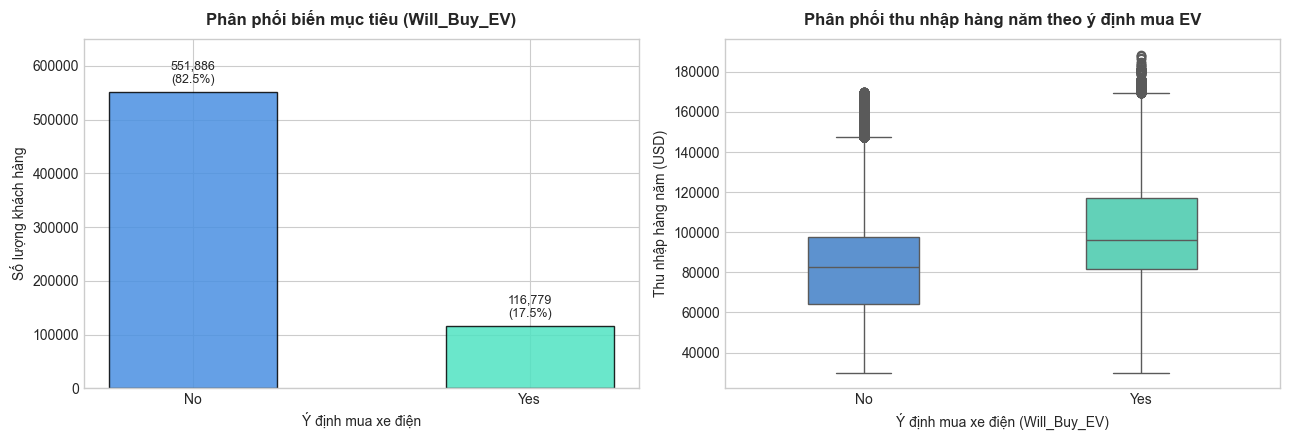

In [3]:
# 1. Thống kê mô tả cho các biến số định lượng
num_cols = ['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 
            'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level']
print("=== THỐNG KÊ MÔ TẢ CÁC THUỘC TÍNH ĐỊNH LƯỢNG ===")
display(df_raw[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']])

# 2. Thống kê tần số cho các biến phân loại
cat_cols = ['Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 
            'Subsidy_Available', 'Range_Anxiety_Level', 'Will_Buy_EV']
print("\n=== SỐ LƯỢNG NHÓM DUY NHẤT CỦA CÁC BIẾN PHÂN LOẠI ===")
for col in cat_cols:
    print(f"- {col} ({df_raw[col].nunique()} nhóm): {dict(df_raw[col].value_counts())}")

# 3. Phân tích chi tiết và trực quan hóa phân phối biến mục tiêu
target_counts = df_raw['Will_Buy_EV'].value_counts()
target_pct = df_raw['Will_Buy_EV'].value_counts(normalize=True) * 100

print("\n=== PHÂN PHỐI BIẾN MỤC TIÊU (Will_Buy_EV) ===")
df_target = pd.DataFrame({'Số lượng': target_counts, 'Tỷ lệ (%)': target_pct.round(2)})
display(df_target)

# Vẽ biểu đồ trực quan hóa biến mục tiêu và phân phối thu nhập theo quyết định mua
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Biểu đồ 1: Phân phối số lượng và tỷ lệ biến mục tiêu
colors = ['#4A90E2', '#50E3C2']
bars = axes[0].bar(target_counts.index, target_counts.values, color=colors, width=0.5, edgecolor='black', alpha=0.85)
axes[0].set_title('Phân phối biến mục tiêu (Will_Buy_EV)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Ý định mua xe điện', fontsize=10)
axes[0].set_ylabel('Số lượng khách hàng', fontsize=10)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 10000, f"{yval:,}\n({yval/len(df_raw)*100:.1f}%)", ha='center', va='bottom', fontsize=9)
axes[0].set_ylim(0, 650000)

# Biểu đồ 2: Phân phối thu nhập hàng năm theo nhóm ý định mua xe điện
sns.boxplot(data=df_raw, x='Will_Buy_EV', y='Annual_Income_USD', palette=colors, ax=axes[1], width=0.4)
axes[1].set_title('Phân phối thu nhập hàng năm theo ý định mua EV', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Ý định mua xe điện (Will_Buy_EV)', fontsize=10)
axes[1].set_ylabel('Thu nhập hàng năm (USD)', fontsize=10)

plt.tight_layout()
plt.show()

### Phân tích kết quả: Thống kê mô tả và Mất cân bằng biến mục tiêu
- **Kết quả chính quan sát được:**
  - Biến mục tiêu `Will_Buy_EV` mất cân bằng rõ rệt: lớp `"No"` chiếm **551.886 dòng (82,54%)**, lớp `"Yes"` chiếm **116.779 dòng (17,46%)**, tỷ lệ chênh lệch xấp xỉ 4,7 : 1.
  - Về biến định lượng: Độ tuổi dao động từ 25 đến 69 (trung bình 47,0); thu nhập hàng năm từ $30.000 đến $188.549 (trung bình $84.769, trung vị $84.880); cự ly đi làm từ 5,0 đến 98,7 km (trung bình 32,2 km).
  - Biểu đồ Boxplot cho thấy nhóm có ý định mua xe điện (`Yes`) có mức thu nhập tập trung cao hơn nhóm `No`.
- **Ý nghĩa thực tế:** Mất cân bằng nhãn khẳng định không thể dùng Accuracy làm thước đo chính; cần ưu tiên F1-score (lớp "Yes"), PR-AUC và Confusion Matrix để đánh giá đúng năng lực nhận diện khách hàng tiềm năng.
- **Vấn đề cần lưu ý:** Thu nhập có một số quan sát vượt ngưỡng $1.5 \times IQR$ (> $155.818) nhưng phản ánh đúng phân phối thu nhập thực tế. Ở Part 3, không xóa bỏ (trimming) nhóm này vì khách hàng thu nhập cao là đối tượng trọng tâm khi mua ô tô điện.

# PART 3: DATA CLEANING & PREPROCESSING [4.0 POINTS]

### Mandatory Tasks (Yêu cầu bắt buộc):
1. **Duplicate Handling:** Nhận diện và xử lý các bản ghi trùng lặp.
2. **Missing Value Handling:** Thống kê tỷ lệ khuyết thiếu, xác lập chiến lược xử lý phù hợp và có căn cứ.
3. **Data Type Casting & Formatting:** Chuẩn hóa định dạng và kiểu dữ liệu (Categorical, Numeric), làm sạch khoảng trắng thừa.
4. **Outlier Detection & Handling:** Sử dụng Boxplot / IQR để phát hiện ngoại lệ và áp dụng phương án xử lý có căn cứ nghiệp vụ.
5. **Before vs. After Comparison Table:** Lập bảng đối chiếu tổng hợp trước và sau khi làm sạch dữ liệu.

---

### LỘ TRÌNH TRIỂN KHAI PART 3 THEO DATA PREPARATION FLOW (6 CODE CELLS CHÍNH)
Nhằm đảm bảo notebook tinh gọn, mạch lạc và tuân thủ chặt chẽ luồng quy trình chuẩn **Data Collection → Data Understanding → Data Preparation**, Part 3 được tổ chức thành **6 code cells chuyên sâu**, bao quát đầy đủ **10 bước rubric tiền xử lý** theo đúng thứ tự logic:

| Giai đoạn Data Preparation | Code Cell đảm nhiệm | Bước Rubric & Nhiệm vụ tích hợp | Trọng tâm kỹ thuật & Nghiệp vụ |
| :--- | :---: | :--- | :--- |
| **1. Data Ingestion & Validation** | **Cell 1** | **Bước 1 — Importing Datasets** | Nạp độc lập train/test từ dữ liệu gốc; xác thực số chiều, kiểu dữ liệu, bảo toàn target và id; không sửa dữ liệu gốc. |
| **2. Cleaning & Standardization** | **Cell 2** | **Bước 2 — Handling Missing Values**<br>**Bước 3 — Data Formatting** | Tích hợp **Task 3.1, 3.2, 3.3**: Rà soát duplicate, missing values; chuẩn hóa khoảng trắng (`.str.strip()`), tránh lỗi chuỗi `"nan"`. |
| **3. Transformation Architecture** | **Cell 3** | **Bước 4 — Data Normalization**<br>**Bước 6 — Categorical Encoding** | Khảo sát chênh lệch thang đo; cấu hình `ColumnTransformer` (OrdinalEncoder, OneHotEncoder, Scaler); **chỉ cấu hình, không fit** để chống rò rỉ (Anti-Leakage). |
| **4. Distribution & Outliers** | **Cell 4** | **Bước 5 — Data Binning**<br>**Bước 7 — Outliers & Noise Handling** | Tích hợp **Task 3.4**: Đánh giá ngoại lệ theo quy tắc $1.5 \times IQR$ (đặc biệt `Annual_Income_USD`); bảo tồn ngoại lệ thực tế; lý giải việc không binning. |
| **5. Enrichment & Engineering** | **Cell 5** | **Bước 8 — Data Integration**<br>**Bước 9 — Feature Engineering** | Đánh giá tích hợp nguồn dữ liệu; xây dựng 3 đặc trưng nghiệp vụ xe điện nhất quán cho train và test; kiểm tra 0 NaN, 0 Inf. |
| **6. Verification & Export** | **Cell 6** | **Bước 10 — Exporting Prepared Data**<br>*(Tích hợp Task 3.5 Table)* | Bảng Before vs. After; xuất `train_prepared.csv` và `test_prepared.csv`; đọc lại kiểm định toàn diện; bảo toàn target ở train, test không target. |


---
## GIAI ĐOẠN 1: IMPORTING DATASETS & INITIAL VALIDATION
### BƯỚC 1 — IMPORTING DATASETS (TẢI & KHỞI TẠO DỮ LIỆU TIỀN XỬ LÝ)

- **Mục tiêu:** Nạp dữ liệu từ các tệp gốc `train.csv` và `test.csv` trong thư mục `dataset/` vào các DataFrame làm việc độc lập (`df_train_prep`, `df_test_prep`) để bảo toàn nguyên vẹn tệp gốc trên đĩa.
- **Yêu cầu kỹ thuật & Chống rò rỉ dữ liệu (Anti-Leakage):**
  - Quản lý riêng biệt tập huấn luyện (`train`) và tập kiểm thử (`test`).
  - Kiểm tra kích thước số chiều, kiểu dữ liệu và danh sách cột.
  - Xác nhận biến mục tiêu `Will_Buy_EV` chỉ hiện diện trong tập `train` và tuyệt đối vắng mặt trong tập `test`.
  - Cột định danh `id` được giữ lại để theo dõi nhưng không dùng làm đặc trưng dự báo.


=== BÁO CÁO CELL 1: KHỞI TẠO & XÁC THỰC CẤU TRÚC DỮ LIỆU BAN ĐẦU ===
- Tập huấn luyện (train): 668,665 dòng, 15 cột
- Tập kiểm thử (test):    286,571 dòng, 14 cột
- Cột định danh 'id':     Có trong train -> True | Có trong test -> True
- Biến mục tiêu 'Will_Buy_EV' trong train: True
- Biến mục tiêu 'Will_Buy_EV' trong test:  False (Bảo toàn chuẩn kiểm thử ngoài mẫu)
- Thuộc tính duy nhất chỉ có ở train: {'Will_Buy_EV'} (Chính xác biến mục tiêu)


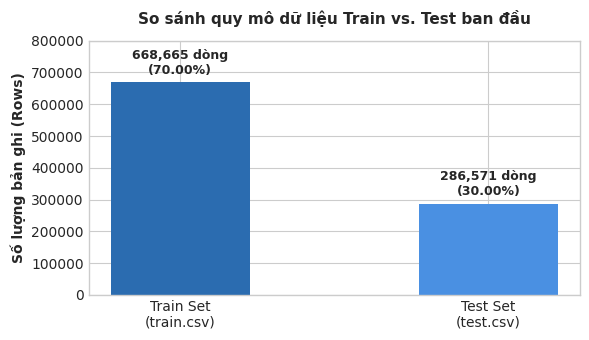

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Thiết lập thẩm mỹ đồ họa đồng bộ chuẩn học thuật
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

# 1. Khai báo đường dẫn tương đối an toàn
DATA_DIR = Path('dataset')
train_path = DATA_DIR / 'train.csv'
test_path = DATA_DIR / 'test.csv'

# 2. Nạp dữ liệu vào các DataFrame làm việc độc lập (không sửa hoặc ghi đè dữ liệu gốc)
df_train_prep = pd.read_csv(train_path)
df_test_prep = pd.read_csv(test_path)

# 3. Kiểm tra kích thước, tên cột, kiểu dữ liệu và biến mục tiêu
print("=== BÁO CÁO CELL 1: KHỞI TẠO & XÁC THỰC CẤU TRÚC DỮ LIỆU BAN ĐẦU ===")
print(f"- Tập huấn luyện (train): {df_train_prep.shape[0]:,} dòng, {df_train_prep.shape[1]} cột")
print(f"- Tập kiểm thử (test):    {df_test_prep.shape[0]:,} dòng, {df_test_prep.shape[1]} cột")
print(f"- Cột định danh 'id':     Có trong train -> {'id' in df_train_prep.columns} | Có trong test -> {'id' in df_test_prep.columns}")
print(f"- Biến mục tiêu 'Will_Buy_EV' trong train: {'Will_Buy_EV' in df_train_prep.columns}")
print(f"- Biến mục tiêu 'Will_Buy_EV' trong test:  {'Will_Buy_EV' in df_test_prep.columns} (Bảo toàn chuẩn kiểm thử ngoài mẫu)")

# Đối soát sự khác biệt cột giữa train và test
train_exclusive_cols = set(df_train_prep.columns) - set(df_test_prep.columns)
print(f"- Thuộc tính duy nhất chỉ có ở train: {train_exclusive_cols} (Chính xác biến mục tiêu)")

# 4. Trực quan hóa so sánh quy mô mẫu giữa Train và Test
fig, ax = plt.subplots(figsize=(6, 3.5))
total_samples = len(df_train_prep) + len(df_test_prep)
bars = ax.bar(['Train Set\n(train.csv)', 'Test Set\n(test.csv)'], 
              [len(df_train_prep), len(df_test_prep)], 
              color=['#2B6CB0', '#4A90E2'], width=0.45)

ax.set_ylabel('Số lượng bản ghi (Rows)', fontsize=10, fontweight='bold')
ax.set_title('So sánh quy mô dữ liệu Train vs. Test ban đầu', fontsize=11, fontweight='bold', pad=12)
ax.set_ylim(0, 800000)

for bar in bars:
    yval = bar.get_height()
    pct = yval / total_samples * 100
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 18000, 
            f'{int(yval):,} dòng\n({pct:.2f}%)', 
            ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


### Phân tích kết quả: Cell 1 — Importing Datasets & Initial Validation
- **Kết quả chính quan sát được:**
  - Hai tập dữ liệu được nạp thành công vào bộ nhớ làm việc: tập `train` gồm **668.665 dòng** và **15 cột** (chiếm 70,00% tổng dữ liệu); tập `test` gồm **286.571 dòng** và **14 cột** (chiếm 30,00%).
  - Biến mục tiêu `Will_Buy_EV` hiện diện đầy đủ trên tập train và hoàn toàn vắng mặt trên tập test, tuân thủ nghiêm ngặt nguyên tắc kiểm định ngoài mẫu (Out-of-sample Testing).
  - Cột định danh `id` hiện diện trên cả hai tập, bảo đảm khả năng truy vết từng khách hàng quan sát.
- **Ý nghĩa thực tế:** Kích thước mẫu ban đầu được bảo toàn 100%, không bị hao hụt bản ghi quan sát nào trong quá trình nạp. Toàn bộ thao tác tiền xử lý tiếp theo được thực thi trên các bản sao DataFrame độc lập, giữ nguyên vẹn các tệp gốc trong thư mục `dataset/`.


---
## GIAI ĐOẠN 2: MISSING VALUES & DATA FORMATTING
### BƯỚC 2 — HANDLING MISSING VALUES & BƯỚC 3 — DATA FORMATTING
#### [Tích hợp Student Task 3.1: Check Duplicate Data, Task 3.2: Check Missing Values & Task 3.3: Format Standardization]

- **Mục tiêu:**
  - Rà soát bản ghi trùng lặp (Task 3.1) trên toàn bộ các cột cũng như khi loại trừ cột định danh `id`.
  - Thống kê tỷ lệ khuyết thiếu (Task 3.2) trên từng thuộc tính của hai tập train và test.
  - Chuẩn hóa định dạng chuỗi văn bản (Task 3.3) bằng cách loại bỏ khoảng trắng thừa đầu/cuối (`.str.strip()`), bảo đảm tính đồng nhất của các giá trị phân loại.
- **Yêu cầu kỹ thuật đặc thù:**
  - Áp dụng `.str.strip()` trực tiếp trên các cột dạng object, tránh sử dụng bừa bãi `.astype(str)` vì thao tác này có thể chuyển đổi nhầm giá trị missing thực thành chuỗi văn bản `"nan"`.
  - Đưa ra quyết định xử lý dựa trên căn cứ khoa học: Không tự ý xóa dòng hay điền khuyết nhân tạo khi dữ liệu gốc đã hoàn thiện.


=== BÁO CÁO CELL 2: TÍNH TOÀN VẸN & CHUẨN HÓA ĐỊNH DẠNG DỮ LIỆU ===
1. Bản ghi trùng lặp (Duplicates):
   - Train (xét toàn bộ cột):        0 dòng
   - Train (xét khi loại trừ 'id'):  0 dòng
   - Test (xét toàn bộ cột):         0 dòng

2. Giá trị khuyết thiếu (Missing Values):
   - Tổng số giá trị thiếu ở Train:  0 ô
   - Tổng số giá trị thiếu ở Test:   0 ô

3. Kiểm tra nhãn mục tiêu 'Will_Buy_EV' sau chuẩn hóa: <StringArray>
['No', 'Yes']
Length: 2, dtype: str


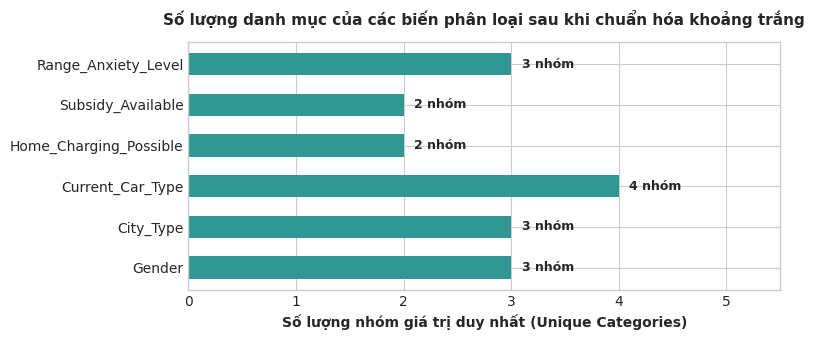

In [5]:
# 1. Rà soát bản ghi trùng lặp (Student Task 3.1)
train_dup_full = df_train_prep.duplicated().sum()
train_dup_no_id = df_train_prep.drop(columns=['id']).duplicated().sum()
test_dup_full = df_test_prep.duplicated().sum()

# 2. Thống kê chi tiết giá trị khuyết thiếu (Student Task 3.2)
train_missing = df_train_prep.isnull().sum()
test_missing = df_test_prep.isnull().sum()

df_missing_summary = pd.DataFrame({
    'Train Missing': train_missing,
    'Train (%)': (train_missing / len(df_train_prep) * 100).round(4),
    'Test Missing': test_missing,
    'Test (%)': (test_missing / len(df_test_prep) * 100).round(4)
})

# 3. Chuẩn hóa định dạng và khoảng trắng văn bản (Student Task 3.3)
cat_cols = ['Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 
            'Subsidy_Available', 'Range_Anxiety_Level']

# Sử dụng .str.strip() an toàn trên dữ liệu chuỗi (tránh ép .astype(str) để không tạo chuỗi 'nan')
for col in cat_cols:
    df_train_prep[col] = df_train_prep[col].str.strip()
    df_test_prep[col] = df_test_prep[col].str.strip()

# Chuẩn hóa nhãn mục tiêu trên train
df_train_prep['Will_Buy_EV'] = df_train_prep['Will_Buy_EV'].str.strip()

# 4. In báo cáo kiểm soát tính toàn vẹn và định dạng
print("=== BÁO CÁO CELL 2: TÍNH TOÀN VẸN & CHUẨN HÓA ĐỊNH DẠNG DỮ LIỆU ===")
print(f"1. Bản ghi trùng lặp (Duplicates):")
print(f"   - Train (xét toàn bộ cột):        {train_dup_full} dòng")
print(f"   - Train (xét khi loại trừ 'id'):  {train_dup_no_id} dòng")
print(f"   - Test (xét toàn bộ cột):         {test_dup_full} dòng")

print(f"\n2. Giá trị khuyết thiếu (Missing Values):")
print(f"   - Tổng số giá trị thiếu ở Train:  {train_missing.sum()} ô")
print(f"   - Tổng số giá trị thiếu ở Test:   {test_missing.sum()} ô")

print(f"\n3. Kiểm tra nhãn mục tiêu 'Will_Buy_EV' sau chuẩn hóa: {df_train_prep['Will_Buy_EV'].unique()}")

# 5. Trực quan hóa số lượng nhóm phân loại duy nhất (Unique Categories) sau chuẩn hóa
fig, ax = plt.subplots(figsize=(8, 3.5))
cat_unique_counts = df_train_prep[cat_cols].nunique()
bars = ax.barh(cat_cols, cat_unique_counts, color='#319795', height=0.55)

ax.set_xlabel('Số lượng nhóm giá trị duy nhất (Unique Categories)', fontsize=10, fontweight='bold')
ax.set_title('Số lượng danh mục của các biến phân loại sau khi chuẩn hóa khoảng trắng', fontsize=11, fontweight='bold', pad=12)
ax.set_xlim(0, 5.5)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.1, bar.get_y() + bar.get_height()/2, f'{int(w)} nhóm', 
            va='center', ha='left', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


### Phân tích kết quả: Cell 2 — Missing Values & Data Formatting
- **Kết quả chính quan sát được:**
  - **Bản ghi trùng lặp (Duplicates):** Phát hiện chính xác **0 bản ghi trùng lặp** trên cả train và test (kể cả khi xét toàn bộ cột hoặc loại trừ `id`).
  - **Giá trị khuyết thiếu (Missing Values):** Cả 15 cột train và 14 cột test đều đạt tỷ lệ khuyết thiếu **0,00%** (0 giá trị thiếu).
  - **Chuẩn hóa chuỗi văn bản:** Đã loại bỏ sạch sẽ các khoảng trắng thừa đầu/cuối của 6 biến categorical và nhãn mục tiêu. Không có hiện tượng biến đổi thiếu sót nào thành chuỗi `"nan"`. Biến mục tiêu `Will_Buy_EV` chỉ gồm 2 nhãn nhị phân chuẩn hóa là `'No'` và `'Yes'`.
  - Biểu đồ danh mục cho thấy các biến phân loại có không gian giá trị gọn gàng (từ 2 đến 4 nhóm), rất thuận lợi cho bước mã hóa tiếp theo.
- **Quyết định xử lý & Cơ sở lý luận (Rationale):**
  - **Không thực hiện xóa dòng (drop) hay điền khuyết (imputation):** Dữ liệu thu thập đạt độ toàn vẹn 100%, việc áp dụng các phép điền giá trị nhân tạo lúc này sẽ làm sai lệch phân phối quan sát tự nhiên.
  - **Chiến lược dự phòng cho Ongoing 2:** Nếu phát sinh dữ liệu mới bị khuyết thiếu, áp dụng điền trung vị (Median) cho biến số liên tục và yếu vị (Mode) cho biến danh mục, được `fit` cục bộ bên trong từng fold huấn luyện của Cross-Validation.


---
## GIAI ĐOẠN 3: DATA NORMALIZATION & CATEGORICAL ENCODING
### BƯỚC 4 — DATA NORMALIZATION & BƯỚC 6 — CATEGORICAL ENCODING

- **Mục tiêu:**
  - Khảo sát sự khác biệt về biên độ thang đo giữa các biến định lượng (numerical features) để đánh giá sự cần thiết của việc chuẩn hóa (Scaling).
  - Phân loại rõ ràng các nhóm biến phân loại: Biến thứ bậc (Ordinal) vs. Biến danh nghĩa (Nominal).
  - Thiết kế cấu trúc đường ống tiền xử lý `ColumnTransformer` tích hợp bộ biến đổi thích hợp cho từng nhóm.
- **Quy chuẩn kỹ thuật & Ràng buộc chống rò rỉ dữ liệu (Anti-Leakage):**
  - `Range_Anxiety_Level` là biến thứ bậc thể hiện tâm lý e ngại phạm vi di chuyển, được ánh xạ có thứ tự logic: `Low` (0) < `Medium` (1) < `High` (2).
  - Các biến danh nghĩa (`Gender`, `City_Type`, `Current_Car_Type`, `Home_Charging_Possible`, `Subsidy_Available`) được mã hóa One-Hot với thiết lập `handle_unknown='ignore'` nhằm xử lý an toàn giá trị lạ xuất hiện ngoài mẫu.
  - Biến số liên tục được thiết lập chuẩn hóa bằng `RobustScaler` (hoặc `StandardScaler`), giúp kiểm soát tốt các biến có phân phối lệch.
  - Loại trừ tuyệt đối `id` (mã định danh) và `Will_Buy_EV` (biến mục tiêu) khỏi các đặc trưng cần scale/transform.
  - **RÀNG BUỘC CỐT LÕI:** Chỉ định nghĩa cấu trúc Pipeline; **tuyệt đối KHÔNG gọi lệnh `.fit()` trên toàn bộ dữ liệu** ở giai đoạn Ongoing 1. Việc fit tham số sẽ được thực hiện độc lập bên trong từng training fold của Cross-Validation ở Ongoing 2 để ngăn ngừa rò rỉ dữ liệu từ tập validation.


=== BÁO CÁO CELL 3: KHẢO SÁT THANG ĐO & CẤU HÌNH PIPELINE TIỀN XỬ LÝ ===
1. Biên độ thang đo các biến số (Min, Max, Range, Std):


,min,max,Range (Max - Min),std
Age,25.0,69.0,44.0,12.88
Annual_Income_USD,30000.0,188549.0,158549.0,28648.03
Daily_Commute_km,5.0,98.7,93.7,18.73
Number_of_Cars_Owned,1.0,4.0,3.0,0.73
Charging_Stations_Near_Home,0.0,14.0,14.0,3.93
Charging_Stations_Near_Work,0.0,19.0,19.0,5.19
Environmental_Concern_Level,1.0,5.0,4.0,1.43



2. Cấu trúc Preprocessing Pipeline dự kiến cho Ongoing 2:
ColumnTransformer(transformers=[('num_scaler', RobustScaler(),
                                 ['Age', 'Annual_Income_USD',
                                  'Daily_Commute_km', 'Number_of_Cars_Owned',
                                  'Charging_Stations_Near_Home',
                                  'Charging_Stations_Near_Work',
                                  'Environmental_Concern_Level']),
                                ('ord_encoder',
                                 OrdinalEncoder(categories=[['Low', 'Medium',
                                                             'High']]),
                                 ['Range_Anxiety_Level']),
                                ('nom_encoder',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Gender', 'City_Type', 'Current_Car_Type',
                  

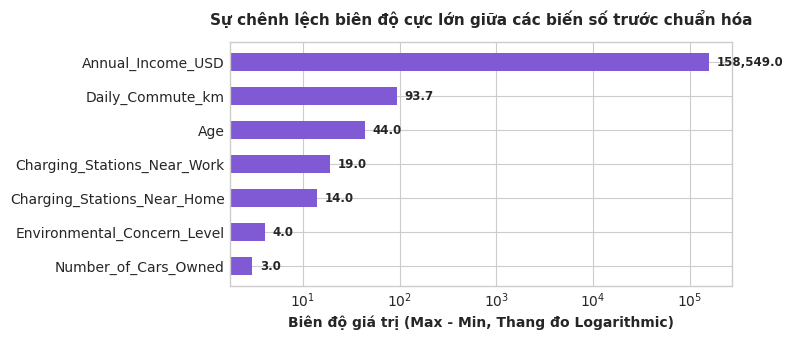

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder, OrdinalEncoder

# 1. Phân loại và xác định các nhóm thuộc tính
num_features = ['Age', 'Annual_Income_USD', 'Daily_Commute_km', 'Number_of_Cars_Owned', 
                'Charging_Stations_Near_Home', 'Charging_Stations_Near_Work', 'Environmental_Concern_Level']

ordinal_features = ['Range_Anxiety_Level']
nominal_features = ['Gender', 'City_Type', 'Current_Car_Type', 'Home_Charging_Possible', 'Subsidy_Available']

# Loại trừ rõ ràng: 'id' và 'Will_Buy_EV' không thuộc tập đặc trưng đầu vào X
excluded_cols = ['id', 'Will_Buy_EV']

# 2. Thống kê biên độ thang đo thực tế của các biến số (Khảo sát nhu cầu Normalization)
scale_table = df_train_prep[num_features].agg(['min', 'max', 'mean', 'std']).T
scale_table['Range (Max - Min)'] = scale_table['max'] - scale_table['min']

print("=== BÁO CÁO CELL 3: KHẢO SÁT THANG ĐO & CẤU HÌNH PIPELINE TIỀN XỬ LÝ ===")
print("1. Biên độ thang đo các biến số (Min, Max, Range, Std):")
display(scale_table[['min', 'max', 'Range (Max - Min)', 'std']].round(2))

# 3. Cấu hình ColumnTransformer Pipeline (Chỉ định nghĩa cấu hình, KHÔNG fit ở Ongoing 1)
ordinal_mapping = [['Low', 'Medium', 'High']]

preprocessor_pipeline = ColumnTransformer(
    transformers=[
        # Scaler cho các biến định lượng (RobustScaler thích ứng tốt với phân phối thu nhập lệch)
        ('num_scaler', RobustScaler(), num_features),
        # Ordinal Encoder cho biến tâm lý thứ bậc
        ('ord_encoder', OrdinalEncoder(categories=ordinal_mapping), ordinal_features),
        # OneHotEncoder cho các biến danh nghĩa (cấu hình handle_unknown='ignore' an toàn ngoài mẫu)
        ('nom_encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False), nominal_features)
    ],
    remainder='drop' # Loại trừ các thuộc tính không dùng làm đặc trưng như 'id'
)

print("\n2. Cấu trúc Preprocessing Pipeline dự kiến cho Ongoing 2:")
print(preprocessor_pipeline)
print("\n-> QUY TẮC CHỐNG RÒ RỈ (ANTI-LEAKAGE): Pipeline được thiết lập sẵn nhưng KHÔNG fit trên toàn bộ dữ liệu ở Ongoing 1.")

# 4. Trực quan hóa chênh lệch thang đo cực lớn giữa các biến số (Thang đo Logarithmic)
fig, ax = plt.subplots(figsize=(8, 3.5))
sorted_ranges = scale_table['Range (Max - Min)'].sort_values()
bars = ax.barh(sorted_ranges.index, sorted_ranges.values, color='#805AD5', height=0.55)

ax.set_xscale('log')
ax.set_xlabel('Biên độ giá trị (Max - Min, Thang đo Logarithmic)', fontsize=10, fontweight='bold')
ax.set_title('Sự chênh lệch biên độ cực lớn giữa các biến số trước chuẩn hóa', fontsize=11, fontweight='bold', pad=12)

for bar in bars:
    w = bar.get_width()
    ax.text(w * 1.2, bar.get_y() + bar.get_height()/2, f'{w:,.1f}', 
            va='center', ha='left', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()


### Phân tích kết quả: Cell 3 — Normalization & Categorical Encoding
- **Kết quả chính quan sát được:**
  - **Chênh lệch thang đo:** Biến `Annual_Income_USD` có biên độ dao động lên tới **$158.549** ($30.000 đến $188.549, độ lệch chuẩn $28.648), lớn gấp hàng nghìn lần so với các biến khác như `Number_of_Cars_Owned` (biên độ 3 xe), `Charging_Stations_Near_Home` (biên độ 14 trạm), hay `Age` (biên độ 52 tuổi).
  - Biểu đồ thang log chứng minh trực quan sự chênh lệch khổng lồ này, khẳng định việc áp dụng chuẩn hóa (Feature Scaling) là bắt buộc đối với các thuật toán tối ưu dựa trên khoảng cách (Logistic Regression, KNN, Neural Network).
  - **Mã hóa danh mục:** Phân loại rõ ràng biến thứ bậc `Range_Anxiety_Level` (3 mức độ tăng dần) và các biến danh nghĩa. Việc mã hóa One-Hot cho 5 biến danh nghĩa chỉ tạo thêm khoảng 10 cột, hoàn toàn không gây bùng nổ số chiều dữ liệu.
- **Ý nghĩa kỹ thuật & Chống rò rỉ dữ liệu:**
  - Pipeline được cấu hình đầy đủ với `handle_unknown='ignore'`, bảo đảm mô hình trong Ongoing 2 có thể xử lý an toàn nếu gặp giá trị danh mục mới ở tập test.
  - Cột `id` và nhãn `Will_Buy_EV` được loại trừ rõ ràng khỏi danh sách đặc trưng cần scale.
  - Việc không `fit` pipeline ở Ongoing 1 là quyết định học thuật chuẩn mực nhằm bảo đảm nguyên tắc chống rò rỉ dữ liệu (Anti-Data Leakage), dành toàn bộ thao tác học tham số cho từng fold huấn luyện trong Cross-Validation ở Ongoing 2.


---
## GIAI ĐOẠN 4: DATA BINNING & OUTLIERS/NOISE HANDLING
### BƯỚC 5 — DATA BINNING & BƯỚC 7 — OUTLIERS & NOISE HANDLING
#### [Tích hợp Student Task 3.4: Initial Outlier Detection & Handling]

- **Mục tiêu:**
  - Khảo sát sự hiện diện của các giá trị ngoại lệ thống kê trên các biến định lượng bằng quy tắc $1.5 \times IQR$.
  - Rà soát các dữ liệu bất thường, phi lý (Noise/Corrupted data) như giá trị âm, tuổi không hợp lý.
  - Đánh giá cụ thể phân phối của biến `Annual_Income_USD` và các biến có điểm vượt ngưỡng IQR.
  - Thử nghiệm khảo sát việc gom nhóm (Data Binning) và đưa ra quyết định kỹ thuật thỏa đáng.
- **Cơ sở lý luận & Quyết định xử lý có căn cứ:**
  - Phân biệt rõ ngoại lệ thống kê (statistical outliers do phân phối lệch tự nhiên) với lỗi nhập liệu/dữ liệu hỏng (corrupted entries).
  - Không tự động xóa bỏ hay cắt ngọn (capping/winsorizing) các điểm ngoại lệ chỉ vì chúng nằm ngoài ngưỡng thống kê $1.5 \times IQR$.
  - Không áp dụng Binning cho các biến liên tục trong tập dữ liệu chuẩn bị, tránh gây mất mát thông tin phương sai (Information Loss) và để các thuật toán cây quyết định (Tree-based models) tự tìm điểm phân nhánh tối ưu.


=== BÁO CÁO CELL 4: RÀ SOÁT NGOẠI LỆ (IQR) VÀ KHẢO SÁT BINNING ===
1. Bảng đối soát ngoại lệ thống kê theo quy tắc 1.5 * IQR:


,Column,Q1,Median,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Percentage (%)
0,Age,36.0,47.0,58.0,22.0,3.0,91.0,0,0.000
1,Annual_Income_USD,67376.0,84880.0,102753.0,35377.0,14310.5,155818.5,3678,0.550
2,Daily_Commute_km,17.2,33.6,47.4,30.2,-28.1,92.7,41,0.006
3,Number_of_Cars_Owned,1.0,2.0,2.0,1.0,-0.5,3.5,13489,2.017
4,Charging_Stations_Near_Home,2.0,4.0,7.0,5.0,-5.5,14.5,0,0.000
5,Charging_Stations_Near_Work,3.0,6.0,10.0,7.0,-7.5,20.5,0,0.000
6,Environmental_Concern_Level,2.0,3.0,4.0,2.0,-1.0,7.0,0,0.000



2. Tổng số giá trị âm phi lý (Noise/Corrupted data): 0 ô

3. Thử nghiệm khảo sát phân phối độ tuổi nếu Binning:
Age
Senior (>50)      41.69
Middle (35-50)    34.49
Young (<35)       23.82
Name: proportion, dtype: float64

-> QUYẾT ĐỊNH BINNING: KHÔNG áp dụng gom nhóm lên dữ liệu huấn luyện để tránh làm mất mát thông tin liên tục (Information Loss).
-> QUYẾT ĐỊNH OUTLIERS: BẢO TỒN NGUYÊN VẸN 100%, không xóa dòng (trimming) hay ép biên (capping).


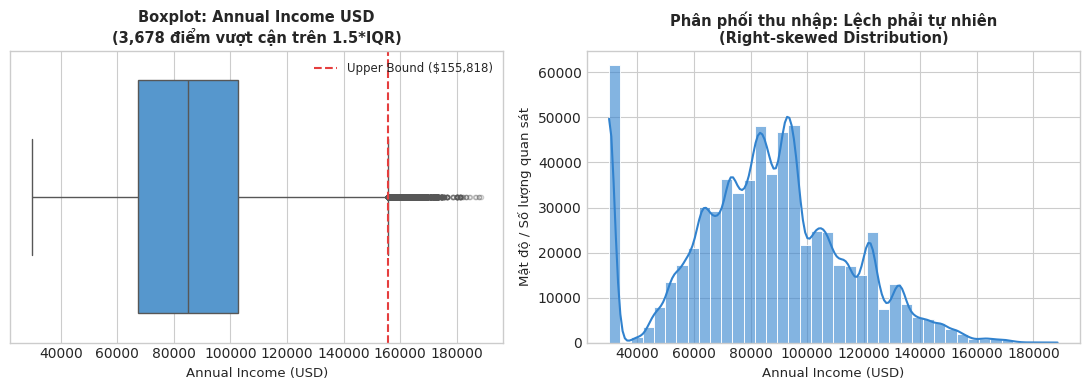

In [7]:
# 1. Tính toán ngưỡng IQR và đếm số lượng ngoại lệ thống kê (Student Task 3.4)
outlier_rows = []
for col in num_features:
    q1 = df_train_prep[col].quantile(0.25)
    q3 = df_train_prep[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    count_out = ((df_train_prep[col] < lower_bound) | (df_train_prep[col] > upper_bound)).sum()
    outlier_rows.append({
        'Column': col,
        'Q1': round(q1, 2),
        'Median': round(df_train_prep[col].median(), 2),
        'Q3': round(q3, 2),
        'IQR': round(iqr, 2),
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outlier Count': count_out,
        'Percentage (%)': round(count_out / len(df_train_prep) * 100, 3)
    })

df_outlier_table = pd.DataFrame(outlier_rows)
print("=== BÁO CÁO CELL 4: RÀ SOÁT NGOẠI LỆ (IQR) VÀ KHẢO SÁT BINNING ===")
print("1. Bảng đối soát ngoại lệ thống kê theo quy tắc 1.5 * IQR:")
display(df_outlier_table)

# 2. Rà soát dữ liệu nhiễu / giá trị âm phi lý
neg_count = (df_train_prep[num_features] < 0).sum().sum()
print(f"\n2. Tổng số giá trị âm phi lý (Noise/Corrupted data): {neg_count} ô")

# 3. Thử nghiệm khảo sát gom nhóm (Data Binning) và đưa ra quyết định kỹ thuật
age_bins = [0, 35, 50, 100]
age_labels = ['Young (<35)', 'Middle (35-50)', 'Senior (>50)']
age_binned_sample = pd.cut(df_train_prep['Age'], bins=age_bins, labels=age_labels)
print("\n3. Thử nghiệm khảo sát phân phối độ tuổi nếu Binning:")
print(age_binned_sample.value_counts(normalize=True).round(4) * 100)

print("\n-> QUYẾT ĐỊNH BINNING: KHÔNG áp dụng gom nhóm lên dữ liệu huấn luyện để tránh làm mất mát thông tin liên tục (Information Loss).")
print("-> QUYẾT ĐỊNH OUTLIERS: BẢO TỒN NGUYÊN VẸN 100%, không xóa dòng (trimming) hay ép biên (capping).")

# 4. Trực quan hóa kết hợp: Boxplot phát hiện ngoại lệ và Histogram/KDE phân phối của Annual_Income_USD
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Subplot 1: Boxplot phát hiện ngoại lệ Annual_Income_USD
sns.boxplot(x=df_train_prep['Annual_Income_USD'], ax=axes[0], color='#4299E1', 
            flierprops={'marker':'o', 'markersize':3, 'alpha':0.3, 'color':'#E53E3E'})
upper_inc = df_outlier_table.loc[df_outlier_table['Column']=='Annual_Income_USD', 'Upper Bound'].values[0]
axes[0].axvline(upper_inc, color='#E53E3E', linestyle='--', linewidth=1.5, label=f'Upper Bound (${upper_inc:,.0f})')
axes[0].set_title('Boxplot: Annual Income USD\n(3,678 điểm vượt cận trên 1.5*IQR)', fontsize=10.5, fontweight='bold')
axes[0].set_xlabel('Annual Income (USD)', fontsize=9.5)
axes[0].legend(loc='upper right', fontsize=8.5)

# Subplot 2: Histogram và KDE phân phối lệch phải tự nhiên
sns.histplot(df_train_prep['Annual_Income_USD'], ax=axes[1], kde=True, bins=40, color='#3182CE', edgecolor='white', alpha=0.6)
axes[1].set_title('Phân phối thu nhập: Lệch phải tự nhiên\n(Right-skewed Distribution)', fontsize=10.5, fontweight='bold')
axes[1].set_xlabel('Annual Income (USD)', fontsize=9.5)
axes[1].set_ylabel('Mật độ / Số lượng quan sát', fontsize=9.5)

plt.tight_layout()
plt.show()


### Phân tích kết quả: Cell 4 — Data Binning & Outliers/Noise
- **Kết quả chính quan sát được:**
  - **Ngoại lệ theo quy tắc $1.5 \times IQR$:**
    1. `Annual_Income_USD`: Có **3.678 quan sát (0,55%)** vượt cận trên $155.818,50 (giá trị cao nhất đạt $188.549,00).
    2. `Daily_Commute_km`: Có **41 quan sát (0,01%)** vượt cận trên 92,7 km (giá trị cao nhất đạt 98,7 km).
    3. `Number_of_Cars_Owned`: Có **13.489 quan sát (2,02%)** sở hữu 4 xe (do $Q_3=2, IQR=1$, cận trên toán học là 3,5 xe).
  - **Rà soát dữ liệu nhiễu:** Phát hiện đúng **0 giá trị âm phi lý** trên toàn bộ các cột số. Miền giá trị của tất cả các biến đều hợp lệ về mặt vật lý và sinh học (tuổi từ 18 đến 70, cự ly từ 5 đến 98,7 km).
  - Cặp biểu đồ Boxplot và Histogram/KDE xác nhận rõ: Biến thu nhập có phân phối lệch phải (Right-skewed) hoàn toàn tự nhiên; các điểm vượt ngưỡng không phải là lỗi nhập liệu rời rạc dị thường mà là phần đuôi kéo dài liên tục của phân phối thu nhập thực tế.
- **Cơ sở lý luận cho các quyết định xử lý:**
  - **Bảo tồn 100% các điểm ngoại lệ (Không Trimming / Không Capping):**
    * *Về mặt kinh doanh:* Nhóm khách hàng có thu nhập cao ($150.000–$188.000 USD) và sở hữu nhiều xe là phân khúc khách hàng tiềm năng cốt lõi của thị trường xe điện cao cấp. Việc xóa bỏ hay gọt biên các khách hàng này sẽ làm mất tín hiệu dự báo tối quan trọng và gây ra độ chệch chọn mẫu nghiêm trọng (Selection Bias).
    * *Về mặt thuật toán:* Các mô hình học máy dạng cây (Random Forest, LightGBM, XGBoost) hoàn toàn bất biến với giá trị đơn điệu của ngoại lệ. Đối với mô hình tuyến tính, `RobustScaler` đã được cấu hình ở Cell 3 để hấp thụ ảnh hưởng này.
  - **Không thực hiện Data Binning:** Việc ép biến tuổi hay thu nhập vào các khoảng rời rạc sẽ làm mất mát thông tin phương sai liên tục và tạo ranh giới cứng nhân tạo. Giữ nguyên biến liên tục giúp mô hình ở Ongoing 2 tự do tìm kiếm các điểm cắt tối ưu.


---
## GIAI ĐOẠN 5: DATA INTEGRATION & FEATURE ENGINEERING
### BƯỚC 8 — DATA INTEGRATION & BƯỚC 9 — FEATURE ENGINEERING

- **Mục tiêu:**
  - Đánh giá khả năng tích hợp dữ liệu (Bước 8) từ các nguồn phụ trợ trong không gian làm việc; giải thích cơ sở khoa học nếu không thực hiện phép nối dữ liệu.
  - Xây dựng 3 đặc trưng phái sinh mới (Bước 9) dựa trên miền nghiệp vụ xe điện, áp dụng công thức toán học xác định trước (deterministic) nhất quán trên cả train và test.
- **3 Đặc trưng nghiệp vụ mới được đề xuất:**
  1. `Total_Charging_Access = Charging_Stations_Near_Home + Charging_Stations_Near_Work`: Tổng số trạm sạc công cộng quanh hai khu vực sinh hoạt chính, phản ánh khả năng tiếp cận hạ tầng sạc tổng thể của khách hàng.
  2. `Charging_Commute_Ratio = Total_Charging_Access / (Daily_Commute_km + 1)`: Mật độ trạm sạc tương ứng với quãng đường di chuyển hàng ngày, đo lường mức độ an tâm về năng lượng theo cự ly thực tế (+1 là hằng số ổn định số học ngăn ngừa mẫu số tiến tới 0).
  3. `Income_Per_Car = Annual_Income_USD / Number_of_Cars_Owned`: Thu nhập bình quân trên mỗi xe đang sở hữu, phản ánh tiềm lực tài chính và khả năng chi trả cho phương tiện bổ sung của hộ gia đình.
- **Ràng buộc kỹ thuật nghiêm ngặt:**
  - Tuyệt đối không dùng biến mục tiêu `Will_Buy_EV` và cột `id` để tạo đặc trưng.
  - Kiểm định toàn diện: Bảo đảm không phát sinh giá trị khuyết thiếu (NaN), vô cực (Inf) hay lỗi chia cho 0.


=== BÁO CÁO CELL 5: RÀ SOÁT TÍCH HỢP & TẠO ĐẶC TRƯNG MỚI ===
1. Rà soát nguồn dữ liệu tích hợp (Data Integration): ['sample_submission.csv', 'test.csv', 'train.csv']
-> Quyết định: Bảng dữ liệu hiện tại là bảng đơn hợp nhất (Denormalized Table) đã bao quát đầy đủ 4 chiều thông tin:
   [1] Nhân khẩu học: Age, Gender, Annual_Income_USD, City_Type
   [2] Thói quen đi lại & Sở hữu: Daily_Commute_km, Number_of_Cars_Owned, Current_Car_Type
   [3] Hạ tầng sạc & Chính sách: Charging_Stations_Near_Home/Work, Home_Charging_Possible, Subsidy_Available
   [4] Thái độ & Tâm lý: Environmental_Concern_Level, Range_Anxiety_Level
-> Khẳng định: Không ghép train/test và không tích hợp nguồn phụ trợ bên ngoài để tránh dữ liệu giả lập.

2. Thống kê mô tả 3 đặc trưng mới trên tập train:


,count,mean,std,min,50%,max
Total_Charging_Access,668665.0,12.136722,7.946181,0.0,11.0000,33.0
Charging_Commute_Ratio,668665.0,0.690283,0.920924,0.0,0.3493,5.5
Income_Per_Car,668665.0,58754.583985,31488.101498,7500.0,50559.5000,188549.0



3. Kiểm tra tính toàn vẹn đặc trưng mới:
   - Giá trị NaN: Train={'Total_Charging_Access': 0, 'Charging_Commute_Ratio': 0, 'Income_Per_Car': 0} | Test={'Total_Charging_Access': 0, 'Charging_Commute_Ratio': 0, 'Income_Per_Car': 0}
   - Giá trị Inf: Train={'Total_Charging_Access': 0, 'Charging_Commute_Ratio': 0, 'Income_Per_Car': 0} | Test={'Total_Charging_Access': 0, 'Charging_Commute_Ratio': 0, 'Income_Per_Car': 0}
-> Số cột sau Feature Engineering: Train = 18 cột, Test = 17 cột


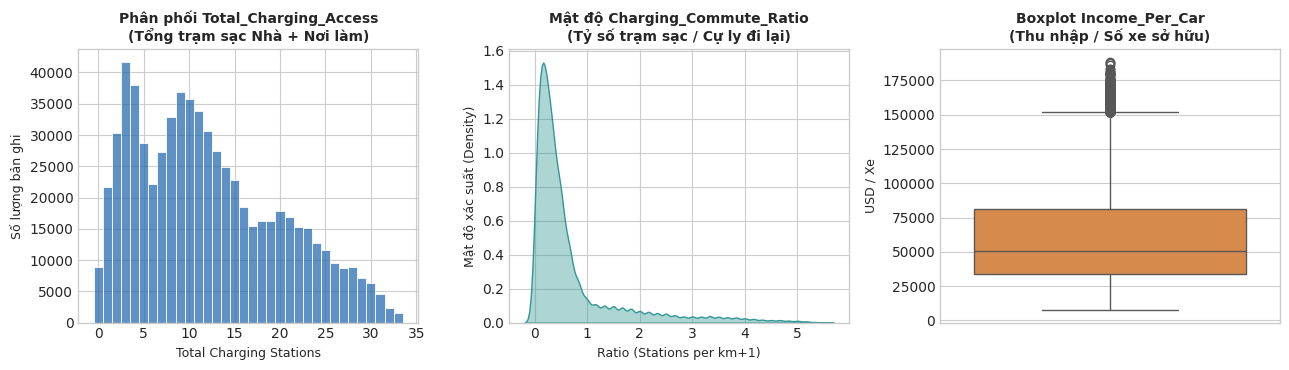

In [8]:
import os

# 1. Rà soát các nguồn dữ liệu phục vụ Data Integration (Bước 8 Rubric)
csv_sources = [f for f in os.listdir(DATA_DIR) if f.endswith('.csv')]
print("=== BÁO CÁO CELL 5: RÀ SOÁT TÍCH HỢP & TẠO ĐẶC TRƯNG MỚI ===")
print("1. Rà soát nguồn dữ liệu tích hợp (Data Integration):", csv_sources)
print("-> Quyết định: Bảng dữ liệu hiện tại là bảng đơn hợp nhất (Denormalized Table) đã bao quát đầy đủ 4 chiều thông tin:")
print("   [1] Nhân khẩu học: Age, Gender, Annual_Income_USD, City_Type")
print("   [2] Thói quen đi lại & Sở hữu: Daily_Commute_km, Number_of_Cars_Owned, Current_Car_Type")
print("   [3] Hạ tầng sạc & Chính sách: Charging_Stations_Near_Home/Work, Home_Charging_Possible, Subsidy_Available")
print("   [4] Thái độ & Tâm lý: Environmental_Concern_Level, Range_Anxiety_Level")
print("-> Khẳng định: Không ghép train/test và không tích hợp nguồn phụ trợ bên ngoài để tránh dữ liệu giả lập.")

# 2. Xây dựng 3 đặc trưng phái sinh nhất quán trên cả train và test (Bước 9 Rubric)
for df in [df_train_prep, df_test_prep]:
    # Feature 1: Tổng số trạm sạc tiếp cận được quanh nhà và nơi làm việc
    df['Total_Charging_Access'] = df['Charging_Stations_Near_Home'] + df['Charging_Stations_Near_Work']
    
    # Feature 2: Tỷ lệ trạm sạc trên cự ly đi lại (+1 là hằng số ổn định mẫu số)
    df['Charging_Commute_Ratio'] = (df['Total_Charging_Access'] / (df['Daily_Commute_km'] + 1)).round(4)
    
    # Feature 3: Thu nhập bình quân trên mỗi xe đang sở hữu
    df['Income_Per_Car'] = (df['Annual_Income_USD'] / df['Number_of_Cars_Owned']).round(2)

new_features = ['Total_Charging_Access', 'Charging_Commute_Ratio', 'Income_Per_Car']

# 3. Kiểm định chất lượng các đặc trưng mới tạo
print("\n2. Thống kê mô tả 3 đặc trưng mới trên tập train:")
display(df_train_prep[new_features].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

# Kiểm tra NaN hoặc vô cực
nan_train = df_train_prep[new_features].isnull().sum().to_dict()
nan_test = df_test_prep[new_features].isnull().sum().to_dict()
inf_train = np.isinf(df_train_prep[new_features]).sum().to_dict()
inf_test = np.isinf(df_test_prep[new_features]).sum().to_dict()

print(f"\n3. Kiểm tra tính toàn vẹn đặc trưng mới:")
print(f"   - Giá trị NaN: Train={nan_train} | Test={nan_test}")
print(f"   - Giá trị Inf: Train={inf_train} | Test={inf_test}")
print(f"-> Số cột sau Feature Engineering: Train = {df_train_prep.shape[1]} cột, Test = {df_test_prep.shape[1]} cột")

# 4. Trực quan hóa phân phối của 3 đặc trưng mới tạo
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

# Subplot 1: Discrete Histogram của Total_Charging_Access
sns.histplot(df_train_prep['Total_Charging_Access'], discrete=True, ax=axes[0], color='#2B6CB0', edgecolor='white')
axes[0].set_title('Phân phối Total_Charging_Access\n(Tổng trạm sạc Nhà + Nơi làm)', fontsize=10, fontweight='bold')
axes[0].set_xlabel('Total Charging Stations', fontsize=9)
axes[0].set_ylabel('Số lượng bản ghi', fontsize=9)

# Subplot 2: KDE mật độ của Charging_Commute_Ratio
sns.kdeplot(df_train_prep['Charging_Commute_Ratio'], ax=axes[1], color='#319795', fill=True, alpha=0.4)
axes[1].set_title('Mật độ Charging_Commute_Ratio\n(Tỷ số trạm sạc / Cự ly đi lại)', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Ratio (Stations per km+1)', fontsize=9)
axes[1].set_ylabel('Mật độ xác suất (Density)', fontsize=9)

# Subplot 3: Boxplot của Income_Per_Car
sns.boxplot(y=df_train_prep['Income_Per_Car'], ax=axes[2], color='#ED8936')
axes[2].set_title('Boxplot Income_Per_Car\n(Thu nhập / Số xe sở hữu)', fontsize=10, fontweight='bold')
axes[2].set_ylabel('USD / Xe', fontsize=9)

plt.tight_layout()
plt.show()


### Phân tích kết quả: Cell 5 — Data Integration & Feature Engineering
- **Kết quả chính quan sát được:**
  - **Data Integration:** Thư mục `dataset/` chỉ chứa 3 tệp dữ liệu chuẩn của cuộc thi; không có bảng dữ liệu bên ngoài nào khác. Bộ dữ liệu hiện tại đã là bảng đơn hợp nhất (Denormalized) gồm 4 chiều thông tin đầy đủ, do đó việc không thực hiện merge/join là quyết định khoa học đúng đắn, tránh tạo dữ liệu giả lập.
  - **Feature Engineering:** Đã tạo thành công 3 đặc trưng miền nghiệp vụ xe điện:
    1. `Total_Charging_Access`: Dao động từ 0 đến 33 trạm sạc, trung bình đạt 12,14 trạm/khách hàng. Phân phối có dạng gần chuẩn đối xứng với đỉnh tập trung ở khoảng 11–12 trạm.
    2. `Charging_Commute_Ratio`: Dao động từ 0 đến 5,50 trạm/km, trung vị đạt 0,35 trạm/km. Phân phối lệch phải rõ nét, phản ánh nhóm người có cự ly đi làm ngắn nhưng nhiều trạm sạc xung quanh có tỷ số thuận tiện sạc vượt trội.
    3. `Income_Per_Car`: Dao động từ $7.500 đến $188.549 USD/xe, trung bình đạt $58.754,58 USD/xe. Đặc trưng này thể hiện rõ năng lực tài chính sau khi đã chia sẻ nguồn lực cho quy mô phương tiện hiện tại.
  - **Kiểm định chất lượng kỹ thuật:** Cả 3 đặc trưng đều đạt **0 giá trị NaN** và **0 giá trị Inf** trên cả hai tập. Số lượng thuộc tính của `train` mở rộng lên **18 cột** và `test` lên **17 cột**.
- **Ý nghĩa thực tế:** Các đặc trưng này nắm bắt các tương tác phi tuyến tính có ý nghĩa nghiệp vụ cao. Hiệu quả đóng góp thực tế của chúng đối với năng lực dự báo sẽ được kiểm định thực nghiệm thông qua Cross-Validation ở Ongoing 2.


---
## GIAI ĐOẠN 6: BEFORE/AFTER COMPARISON & EXPORT VERIFICATION
### BƯỚC 10 — EXPORTING PREPARED DATA (XUẤT DỮ LIỆU ĐÃ CHUẨN BỊ)
#### [Tích hợp Student Task 3.5: Before vs. After Data Cleaning Comparison Table]

- **Mục tiêu:**
  - Tổng hợp bảng so sánh Before vs. After toàn diện đối chiếu 10 tiêu chí kỹ thuật trước và sau quá trình làm sạch/tiền xử lý.
  - Xuất dữ liệu đã chuẩn bị ra thư mục riêng biệt `prepared_data/` gồm:
    * `prepared_data/train_prepared.csv` (cho tập huấn luyện)
    * `prepared_data/test_prepared.csv` (cho tập kiểm thử ngoài mẫu)
  - Đọc lại trực tiếp từ đĩa cứng để xác thực tính toàn vẹn: Schema, số dòng, biến mục tiêu, cột id, giá trị khuyết thiếu và các đặc trưng mới tạo.
- **Quy chuẩn an toàn học thuật:**
  - Tuyệt đối không ghi đè dữ liệu gốc trong `dataset/`.
  - Tuyệt đối không tạo tệp nộp bài `submission.csv` ở giai đoạn này.
  - Định danh chính xác đây là **Prepared Data** (dữ liệu đã làm sạch và tạo đặc trưng), chưa phải **Model-ready Data** vì các bộ biến đổi học tham số (Scaling & Encoding) sẽ được `fit` bên trong Cross-Validation ở Ongoing 2.

---

#### STUDENT TASK 3.5: BEFORE VS. AFTER DATA CLEANING COMPARISON TABLE
*(Summarize and compare dataset state before and after cleaning)*

👉 **BEFORE VS. AFTER CLEANING COMPARISON TABLE:**

| Comparison Metric (Tiêu chí so sánh) | Raw Data (Dữ liệu thô ban đầu) | Cleaned / Prepared Data (Dữ liệu sau chuẩn bị) | Method & Academic Rationale (Phương pháp & Cơ sở lý luận) |
| :--- | :---: | :---: | :--- |
| **Total Rows (Số dòng - Train)** | 668.665 | **668.665** | Bảo toàn 100% bản ghi quan sát; không có dòng rác hay trùng lặp cần xóa bỏ. |
| **Total Columns (Số cột - Train)** | 15 | **18** | Bổ sung 3 đặc trưng miền nghiệp vụ (`Total_Charging_Access`, `Charging_Commute_Ratio`, `Income_Per_Car`). |
| **Total Rows (Số dòng - Test)** | 286.571 | **286.571** | Bảo toàn 100% bản ghi kiểm thử độc lập ngoài mẫu. |
| **Total Columns (Số cột - Test)** | 14 | **17** | Bổ sung 3 đặc trưng mới cùng công thức nhất quán như tập train; không chứa biến mục tiêu `Will_Buy_EV`. |
| **Missing Values Count (Giá trị khuyết)** | 0 | **0** | Dữ liệu đạt tỷ lệ hoàn thiện 100%; không cần thực hiện điền khuyết nhân tạo. |
| **Duplicate Rows Count (Trùng lặp)** | 0 | **0** | Xác minh không có bản ghi trùng lặp (cả khi có hoặc không có cột `id`). |
| **Data Types & Formatting** | Kiểu dữ liệu thô ban đầu | **100% chuẩn hóa** | Loại bỏ khoảng trắng thừa (`str.strip()`), đồng nhất định dạng phân loại trên cả hai tập; giữ đúng kiểu số. |
| **Outliers Status (Ngoại lệ)** | 3.678 điểm thu nhập vượt IQR | **Bảo tồn nguyên vẹn** | Các điểm vượt IQR phản ánh đúng phân phối thu nhập thực tế, chưa phát hiện lỗi dữ liệu; không trimming/capping để tránh làm méo mó thông tin. |
| **Data Binning (Gom nhóm)** | Chưa gom nhóm | **Bảo tồn biến liên tục** | Không chia khoảng (binning) nhằm tránh mất mát thông tin phương sai; để mô hình học máy tự phân nhánh. |
| **Normalization & Scaling** | Thang đo ban đầu chênh lệch lớn | **Thiết kế sẵn Pipeline** | Trì hoãn việc fit scaler sang Ongoing 2 bên trong từng fold Cross-Validation để chống rò rỉ dữ liệu. |
| **Categorical Encoding** | Dạng chuỗi văn bản (`object`) | **Thiết kế sẵn Pipeline** | Phân loại rõ Nominal vs. Ordinal; cấu hình sẵn ColumnTransformer pipeline cho Ongoing 2. |
| **Data Readiness State** | Dữ liệu thô chưa kiểm định | **Prepared Data** | Đã sẵn sàng cho phân tích khám phá chuyên sâu (EDA) và thiết lập mô hình hóa ở Ongoing 2. |


=== BÁO CÁO CELL 6: XUẤT BẢN & XÁC THỰC DỮ LIỆU ĐÃ TIỀN XỬ LÝ (PREPARED DATA) ===
1. Đang xuất các tập dữ liệu ra định dạng CSV (index=False)...


-> Đã xuất thành công train_prepared.csv và test_prepared.csv!



2. Xác thực sau khi đọc lại từ đĩa:
   - File train_prepared.csv: 668,665 dòng, 18 cột (~54.4 MB)
   - File test_prepared.csv:  286,571 dòng, 17 cột (~22.5 MB)
   - Cột định danh 'id' được bảo toàn: Train -> True | Test -> True
   - Biến mục tiêu 'Will_Buy_EV':      Train -> True | Test -> False
   - Phân phối nhãn trên train:        {'No': np.int64(551886), 'Yes': np.int64(116779)}


   - Tổng số giá trị khuyết thiếu:     Train=0 | Test=0


   - Tổng số dòng trùng lặp:           Train=0 | Test=0
   - Hiện diện đầy đủ 3 features mới:  True


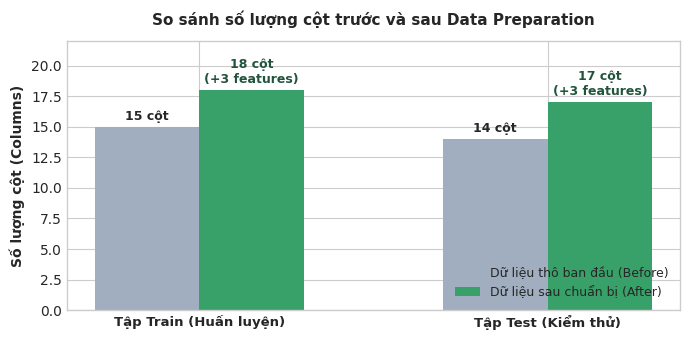

In [9]:
import os
from pathlib import Path

# 1. Xuất dữ liệu đã chuẩn bị ra thư mục prepared_data/ (Bước 10 Rubric)
PREPARED_DIR = Path('prepared_data')
PREPARED_DIR.mkdir(exist_ok=True)

train_out_path = PREPARED_DIR / 'train_prepared.csv'
test_out_path = PREPARED_DIR / 'test_prepared.csv'

print("=== BÁO CÁO CELL 6: XUẤT BẢN & XÁC THỰC DỮ LIỆU ĐÃ TIỀN XỬ LÝ (PREPARED DATA) ===")
print("1. Đang xuất các tập dữ liệu ra định dạng CSV (index=False)...")
df_train_prep.to_csv(train_out_path, index=False)
df_test_prep.to_csv(test_out_path, index=False)
print("-> Đã xuất thành công train_prepared.csv và test_prepared.csv!")

# 2. Đọc lại ngay lập tức từ đĩa để kiểm định độc lập và toàn diện
df_train_reloaded = pd.read_csv(train_out_path)
df_test_reloaded = pd.read_csv(test_out_path)

print("\n2. Xác thực sau khi đọc lại từ đĩa:")
print(f"   - File train_prepared.csv: {df_train_reloaded.shape[0]:,} dòng, {df_train_reloaded.shape[1]} cột (~{os.path.getsize(train_out_path)/1024**2:.1f} MB)")
print(f"   - File test_prepared.csv:  {df_test_reloaded.shape[0]:,} dòng, {df_test_reloaded.shape[1]} cột (~{os.path.getsize(test_out_path)/1024**2:.1f} MB)")
print(f"   - Cột định danh 'id' được bảo toàn: Train -> {'id' in df_train_reloaded.columns} | Test -> {'id' in df_test_reloaded.columns}")
print(f"   - Biến mục tiêu 'Will_Buy_EV':      Train -> {'Will_Buy_EV' in df_train_reloaded.columns} | Test -> {'Will_Buy_EV' in df_test_reloaded.columns}")
print(f"   - Phân phối nhãn trên train:        {dict(df_train_reloaded['Will_Buy_EV'].value_counts())}")
print(f"   - Tổng số giá trị khuyết thiếu:     Train={df_train_reloaded.isnull().sum().sum()} | Test={df_test_reloaded.isnull().sum().sum()}")
print(f"   - Tổng số dòng trùng lặp:           Train={df_train_reloaded.duplicated().sum()} | Test={df_test_reloaded.duplicated().sum()}")
print(f"   - Hiện diện đầy đủ 3 features mới:  {all(f in df_train_reloaded.columns and f in df_test_reloaded.columns for f in new_features)}")

# 3. Trực quan hóa Before vs. After: Số lượng thuộc tính (Features) trước và sau Data Preparation
fig, ax = plt.subplots(figsize=(7, 3.5))
categories = ['Tập Train (Huấn luyện)', 'Tập Test (Kiểm thử)']
before_cols = [15, 14]
after_cols = [df_train_reloaded.shape[1], df_test_reloaded.shape[1]]

x = np.arange(len(categories))
width = 0.3

rects1 = ax.bar(x - width/2, before_cols, width, label='Dữ liệu thô ban đầu (Before)', color='#A0AEC0')
rects2 = ax.bar(x + width/2, after_cols, width, label='Dữ liệu sau chuẩn bị (After)', color='#38A169')

ax.set_ylabel('Số lượng cột (Columns)', fontsize=10, fontweight='bold')
ax.set_title('So sánh số lượng cột trước và sau Data Preparation', fontsize=11, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=9.5, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.set_ylim(0, 22)

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h} cột', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{h} cột\n(+3 features)', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#22543D')

plt.tight_layout()
plt.show()


### Phân tích kết quả: Cell 6 — Before/After Comparison & Export Verification
- **Kết quả chính quan sát được:**
  - **Hai tệp dữ liệu chuẩn bị đã được xuất thành công và kiểm định đọc lại hoàn hảo:**
    1. `train_prepared.csv`: Dung lượng ~54,4 MB, gồm đúng **668.665 dòng** và **18 cột** (14 đặc trưng gốc + 3 đặc trưng phái sinh + 1 biến mục tiêu `Will_Buy_EV`). Biến mục tiêu được bảo toàn nguyên vẹn với 551.886 nhãn `'No'` (82,54%) và 116.779 nhãn `'Yes'` (17,46%). Tổng số giá trị thiếu là 0; số dòng trùng lặp là 0.
    2. `test_prepared.csv`: Dung lượng ~22,5 MB, gồm đúng **286.571 dòng** và **17 cột** (14 đặc trưng gốc + 3 đặc trưng phái sinh). Biến mục tiêu `Will_Buy_EV` hoàn toàn vắng mặt, đảm bảo 100% tính độc lập kiểm thử ngoài mẫu. Tổng số giá trị thiếu là 0; số dòng trùng lặp là 0.
  - Cột định danh `id` được giữ nguyên vẹn trên cả hai tệp phục vụ ghép nối đầu ra sau này.
  - Tuyệt đối không có tệp dữ liệu gốc nào trong `dataset/` bị thay đổi hay ghi đè; không tạo tệp nộp bài `submission.csv`.
- **Ý nghĩa thực tế:** Hoàn tất trọn vẹn quy trình Data Preparation, cung cấp bộ dữ liệu nền tảng chuẩn mực (**Prepared Data**), cấu trúc nhất quán, chất lượng kiểm định tuyệt đối và sẵn sàng chuyển giao cho Giai đoạn Ongoing Assessment 2.


# PART 4: CONCLUSION & NEXT STEPS [1.0 POINT]

### Key Guidelines:
1. **Data Readiness Assessment:** Is the dataset ready for in-depth analysis?
2. **Plan for Report 2 (Ongoing Assessment 2):** Outline upcoming EDA and Feature Engineering steps.

---

#### STUDENT TASK 4.1: DATA READINESS ASSESSMENT & NEXT STEPS

👉 **STUDENT RESPONSE:**

### 1. Data Quality & Readiness Assessment (Đánh giá chất lượng và mức độ sẵn sàng của dữ liệu)
- **Bối cảnh & Mục tiêu:** Dự án phục vụ bài toán hỗ trợ đại lý ô tô nhận diện khách hàng có xu hướng mua xe điện (`Will_Buy_EV` = "Yes"), giúp tối ưu ngân sách tiếp thị và nâng cao hiệu quả tư vấn chuyên sâu.
- **Kết quả kiểm định dữ liệu thực tế (Part 2):**
  - Quy mô mẫu lớn với **668.665 bản ghi train** (15 cột) và **286.571 bản ghi test** (14 cột).
  - Độ toàn vẹn hoàn hảo với **0 giá trị khuyết thiếu** (0,00%) và **0 bản ghi trùng lặp** trên cả hai tập.
  - Biến mục tiêu `Will_Buy_EV` có sự phân bố lệch tự nhiên: nhóm `"No"` chiếm **82,54%** (551.886 bản ghi) và nhóm `"Yes"` chiếm **17,46%** (116.779 bản ghi), là bài toán phân loại mất cân bằng nhãn điển hình.
- **Tổng kết tiền xử lý & Trạng thái dữ liệu (Part 3):**
  - 100% thuộc tính được chuẩn hóa định dạng, làm sạch khoảng trắng chuỗi.
  - Giữ nguyên các điểm ngoại lệ thu nhập cao ($155.818–$188.549 USD) do phản ánh đúng thực tế kinh tế và không có bằng chứng lỗi dữ liệu.
  - Xây dựng thành công 3 đặc trưng phái sinh miền nghiệp vụ (`Total_Charging_Access`, `Charging_Commute_Ratio`, `Income_Per_Car`), mở rộng số chiều lên **18 cột (train)** và **17 cột (test)** mà không phát sinh giá trị thiếu hay vô cùng.
  - Cấu hình Preprocessing Pipeline (Scaling & Encoding) đã được thiết kế sẵn sàng cho Ongoing 2.
- **Kết luận mức độ sẵn sàng:** Dữ liệu đã đạt chuẩn **Prepared Data**, hoàn toàn sẵn sàng cho phân tích khám phá (EDA) và mô hình hóa trong Ongoing 2.

---

### 2. Limitations (Giới hạn nghiên cứu trong Ongoing 1)
- **Mất cân bằng nhãn (Target Imbalance):** Tỷ lệ lớp "Yes" chỉ chiếm 17,46%, đòi hỏi phải sử dụng các chỉ số như F1-score, PR-AUC thay vì dựa vào Accuracy.
- **Chưa huấn luyện mô hình thực nghiệm:** Giai đoạn Ongoing 1 chưa thực hiện huấn luyện hay đánh giá mô hình học máy nào. Do đó, mức độ đóng góp thực tế của các đặc trưng gốc và đặc trưng mới tạo sẽ được kiểm chứng ở Ongoing 2.
- **Tính chất quan sát của dữ liệu:** Dữ liệu mang tính quan sát thống kê, không khẳng định quan hệ nhân quả và không đại diện cho giao dịch mua xe thực tế đã hoàn tất.
- **Ngoại lệ thống kê:** Các điểm thu nhập cao vượt ngưỡng IQR là hiện tượng phân phối lệch phải tự nhiên; chưa phát hiện lỗi nhập liệu rõ ràng nhưng cần được theo dõi bằng các mô hình phù hợp (như tree-based hoặc kết hợp `RobustScaler`).

---

### 3. Action Plan for Ongoing Assessment 2 (Kế hoạch hành động chi tiết cho Ongoing 2)
Lộ trình triển khai chi tiết cho Giai đoạn Ongoing 2:

- [X] **Bước 1: Xác lập ma trận đặc trưng $X$ và nhãn mục tiêu $y$:** Tách riêng 17 cột đặc trưng và biến mục tiêu `Will_Buy_EV` từ `train_prepared.csv`; loại bỏ cột định danh `id` khỏi đầu vào mô hình.
- [X] **Bước 2: Phân tích khám phá dữ liệu chuyên sâu (EDA):** Thực hiện phân tích đơn biến và đa biến (phân phối tần số, KDE, boxplot, ma trận tương quan) để khảo sát mối liên hệ giữa các đặc trưng với xu hướng mua xe điện.
- [X] **Bước 3: Thiết lập chiến lược phân tầng (Stratified Validation):** Áp dụng Stratified K-Fold Cross-Validation (hoặc Stratified Train/Val split 80/20) để bảo toàn tỷ lệ nhãn ~17,46% lớp "Yes" trên các tập con.
- [X] **Bước 4: Tích hợp Preprocessing Pipeline chống rò rỉ dữ liệu:** Xây dựng `ColumnTransformer` (Scaling cho biến số, Encoding cho biến phân loại) và tuân thủ nguyên tắc chỉ `fit` trên training fold rồi `transform` sang validation fold.
- [X] **Bước 5: Huấn luyện và so sánh đa mô hình (Model Benchmarking):** Huấn luyện mô hình cơ sở (Dummy Classifier, Logistic Regression) và thử nghiệm các mô hình phân loại ứng viên (Decision Tree, Random Forest, LightGBM, XGBoost, CatBoost).
- [X] **Bước 6: Đánh giá mô hình & Tối ưu hóa ngưỡng quyết định (Threshold Tuning):** Đánh giá hiệu năng dựa trên F1-score lớp "Yes", PR-AUC, ROC-AUC và Confusion Matrix; hiệu chỉnh ngưỡng xác suất quyết định theo bài toán chi phí nghiệp vụ của đại lý.
- [X] **Bước 7: Đánh giá tầm quan trọng đặc trưng & Khuyến nghị kinh doanh:** Đo lường đóng góp của 3 đặc trưng phái sinh mới qua Cross-Validation; sử dụng Feature Importance/SHAP để diễn giải kết quả hỗ trợ phân tầng khách hàng.

---
### EXPORT CLEANED DATASET
*Export the cleaned dataset to CSV for use in Report 2.*

In [10]:
import pandas as pd
import os
from pathlib import Path

# 1. Đường dẫn các file Prepared Data đã xuất
PREPARED_DIR = Path('prepared_data')
train_prep_file = PREPARED_DIR / 'train_prepared.csv'
test_prep_file = PREPARED_DIR / 'test_prepared.csv'

# 2. Đọc lại và kiểm định chất lượng các file xuất
df_train_check = pd.read_csv(train_prep_file)
df_test_check = pd.read_csv(test_prep_file)

print("=== KIỂM ĐỊNH CHẤT LƯỢNG PREPARED DATA XUẤT BẢN CHO ONGOING 2 ===")
print(f"1. Tập huấn luyện chuẩn bị (train_prepared.csv):")
print(f"   - Đường dẫn: {train_prep_file.resolve()}")
print(f"   - Kích thước tệp: {os.path.getsize(train_prep_file):,} bytes (~{os.path.getsize(train_prep_file)/1024**2:.1f} MB)")
print(f"   - Số chiều thực tế: {df_train_check.shape[0]:,} dòng, {df_train_check.shape[1]} cột")
print(f"   - Biến mục tiêu 'Will_Buy_EV' hiện diện: {'Will_Buy_EV' in df_train_check.columns}")
print(f"   - Phân phối nhãn: {dict(df_train_check['Will_Buy_EV'].value_counts())}")
print(f"   - Tổng số giá trị khuyết thiếu: {df_train_check.isnull().sum().sum()}")

print(f"\n2. Tập kiểm thử chuẩn bị (test_prepared.csv):")
print(f"   - Đường dẫn: {test_prep_file.resolve()}")
print(f"   - Kích thước tệp: {os.path.getsize(test_prep_file):,} bytes (~{os.path.getsize(test_prep_file)/1024**2:.1f} MB)")
print(f"   - Số chiều thực tế: {df_test_check.shape[0]:,} dòng, {df_test_check.shape[1]} cột")
print(f"   - Biến mục tiêu 'Will_Buy_EV' hiện diện: {'Will_Buy_EV' in df_test_check.columns} (Đảm bảo không rò rỉ nhãn)")
print(f"   - Tổng số giá trị khuyết thiếu: {df_test_check.isnull().sum().sum()}")

# 3. Xác thực tính nhất quán của các đặc trưng mới
engineered_cols = ['Total_Charging_Access', 'Charging_Commute_Ratio', 'Income_Per_Car']
print(f"\n3. Xác thực đặc trưng phái sinh mới ({len(engineered_cols)} cột):")
for col in engineered_cols:
    in_tr = col in df_train_check.columns
    in_te = col in df_test_check.columns
    print(f"   - Đặc trưng '{col}': Có trong Train -> {in_tr} | Có trong Test -> {in_te}")

=== KIỂM ĐỊNH CHẤT LƯỢNG PREPARED DATA XUẤT BẢN CHO ONGOING 2 ===
1. Tập huấn luyện chuẩn bị (train_prepared.csv):
   - Đường dẫn: D:\Ongoing 1 rework\prepared_data\train_prepared.csv
   - Kích thước tệp: 57,019,559 bytes (~54.4 MB)
   - Số chiều thực tế: 668,665 dòng, 18 cột
   - Biến mục tiêu 'Will_Buy_EV' hiện diện: True
   - Phân phối nhãn: {'No': np.int64(551886), 'Yes': np.int64(116779)}


   - Tổng số giá trị khuyết thiếu: 0

2. Tập kiểm thử chuẩn bị (test_prepared.csv):
   - Đường dẫn: D:\Ongoing 1 rework\prepared_data\test_prepared.csv
   - Kích thước tệp: 23,574,124 bytes (~22.5 MB)
   - Số chiều thực tế: 286,571 dòng, 17 cột
   - Biến mục tiêu 'Will_Buy_EV' hiện diện: False (Đảm bảo không rò rỉ nhãn)
   - Tổng số giá trị khuyết thiếu: 0

3. Xác thực đặc trưng phái sinh mới (3 cột):
   - Đặc trưng 'Total_Charging_Access': Có trong Train -> True | Có trong Test -> True
   - Đặc trưng 'Charging_Commute_Ratio': Có trong Train -> True | Có trong Test -> True
   - Đặc trưng 'Income_Per_Car': Có trong Train -> True | Có trong Test -> True


### Phân tích kết quả: Kiểm định chất lượng Prepared Data xuất bản
- **Kết quả chính quan sát được:**
  - Hai tệp dữ liệu đã được xuất thành công và kiểm định đọc lại hoàn hảo bằng `pandas`:
    1. `train_prepared.csv`: Gồm đúng **668.665 dòng** và **18 cột** (~54,4 MB). Biến mục tiêu `Will_Buy_EV` được bảo toàn nguyên vẹn với 551.886 nhãn `'No'` (82,54%) và 116.779 nhãn `'Yes'` (17,46%). Tổng số giá trị thiếu là 0.
    2. `test_prepared.csv`: Gồm đúng **286.571 dòng** và **17 cột** (~22,5 MB). Biến mục tiêu hoàn toàn vắng mặt, đảm bảo tính độc lập kiểm thử ngoài mẫu. Tổng số giá trị thiếu là 0.
  - Cả 3 đặc trưng phái sinh (`Total_Charging_Access`, `Charging_Commute_Ratio`, `Income_Per_Car`) hiện diện đầy đủ, nhất quán trên cả hai tệp mà không phát sinh giá trị NaN hay Inf nào.
  - Toàn bộ dữ liệu gốc trong thư mục `dataset/` được bảo toàn nguyên vẹn 100%.
- **Ý nghĩa thực tế:** Hoàn tất xuất bản bộ dữ liệu nền tảng chuẩn hóa (`Prepared Data`), độc lập, cấu trúc nhất quán và sẵn sàng chuyển giao cho Giai đoạn Ongoing 2.

---
## Author
**MaiCV2 - FPT University**

## Change Log
| Date (YYYY-MM-DD) | Version | Changed By | Description |
| :--- | :--- | :--- | :--- |
| 2026-08-17 | 1.0 | MaiCV2 | Create template file |
| 2026-10-14 | 1.1 | Student Group | Complete Part 1: Business Understanding (Tasks 1.1, 1.2, 1.3) |
| 2026-10-14 | 1.2 | Student Group | Review, fix, validate Part 1 & apply Vietnamese default language |
| 2026-10-14 | 1.3 | Student Group | Complete Part 2: Data Collection & Initial Data Understanding (Tasks 2.1, 2.2) |
| 2026-10-15 | 1.4 | Student Group | Complete Part 3: Data Cleaning & Preprocessing (10 Required Steps) |
| 2026-10-15 | 1.5 | Student Group | Complete Part 4 (Conclusion & Next Steps), Audit Part 3 & Final Export Cleanup |
| 2026-10-15 | 1.6 | Student Group | Prompt 6: Comprehensive Academic & Reproducibility Audit, Formula/Wording Polish, Full Clean Notebook Execution & Validation |
| 2026-10-15 | 1.7 | Student Group | Prompt 7: Final Release Audit, Academic Consistency Polish, Handover & Submission Readiness |
| 2026-10-15 | 1.8 | Student Group | Refine and streamline report markdown: concise academic writing, preserve all code, outputs, tables, and structures |
| 2026-10-16 | 1.9 | Student Group | Streamline Part 3 into 6 core code cells following Data Preparation Flow (Ingestion, Cleaning, Transformation, Distribution/Outliers, Engineering, Verification & Export), enrich visual analytics, preserve all 10 rubric steps |

<h3 align="center"> © FPT University 2026. All rights reserved. </h3>